# **Problem Statement**

## Business Context

A sales forecast is a prediction of future sales revenue based on historical data, industry trends, and the status of the current sales pipeline. Businesses use the sales forecast to estimate weekly, monthly, quarterly, and annual sales totals. A company needs to make an accurate sales forecast as it adds value across an organization and helps the different verticals to chalk out their future course of action.

Forecasting helps an organization plan its sales operations by region and provides valuable insights to the supply chain team regarding the procurement of goods and materials. An accurate sales forecast process has many benefits which include improved decision-making about the future and reduction of sales pipeline and forecast risks. Moreover, it helps to reduce the time spent in planning territory coverage and establish benchmarks that can be used to assess trends in the future.

## Objective

SuperKart is a retail chain operating supermarkets and food marts across various tier cities, offering a wide range of products. To optimize its inventory management and make informed decisions around regional sales strategies, SuperKart wants to accurately forecast the sales revenue of its outlets for the upcoming quarter.

To operationalize these insights at scale, the company has partnered with a data science firm—not just to build a predictive model based on historical sales data, but to develop and deploy a robust forecasting solution that can be integrated into SuperKart’s decision-making systems and used across its network of stores.

## Data Description

The data contains the different attributes of the various products and stores.The detailed data dictionary is given below.

- **Product_Id** - unique identifier of each product, each identifier having two letters at the beginning followed by a number.
- **Product_Weight** - weight of each product
- **Product_Sugar_Content** - sugar content of each product like low sugar, regular and no sugar
- **Product_Allocated_Area** - ratio of the allocated display area of each product to the total display area of all the products in a store
- **Product_Type** - broad category for each product like meat, snack foods, hard drinks, dairy, canned, soft drinks, health and hygiene, baking goods, bread, breakfast, frozen foods, fruits and vegetables, household, seafood, starchy foods, others
- **Product_MRP** - maximum retail price of each product
- **Store_Id** - unique identifier of each store
- **Store_Establishment_Year** - year in which the store was established
- **Store_Size** - size of the store depending on sq. feet like high, medium and low
- **Store_Location_City_Type** - type of city in which the store is located like Tier 1, Tier 2 and Tier 3. Tier 1 consists of cities where the standard of living is comparatively higher than its Tier 2 and Tier 3 counterparts.
- **Store_Type** - type of store depending on the products that are being sold there like Departmental Store, Supermarket Type 1, Supermarket Type 2 and Food Mart
- **Product_Store_Sales_Total** - total revenue generated by the sale of that particular product in that particular store


# **Installing and Importing the necessary libraries**

In [1]:
# Use the supplied analysis versions; add the packages needed to run both services
# Install into this notebook's kernel rather than a separate Python environment
%pip install -q numpy==2.0.2 pandas==2.2.2 scikit-learn==1.6.1 matplotlib==3.10.0 seaborn==0.13.2 joblib==1.4.2 xgboost==2.1.4 requests==2.32.4 flask==3.1.2 gunicorn==23.0.0 streamlit==1.43.2

Note: you may need to restart the kernel to use updated packages.


- The main analysis packages keep the versions supplied with the full-code notebook.
- Flask, Gunicorn, and Streamlit are included so the same environment can check the backend and frontend. Flask and Gunicorn use supported versions instead of the older low-code pins.
- On a Mac, XGBoost also needs the OpenMP library. The Docker image installs the corresponding Linux library.
- After the first installation in Colab, restart the runtime and continue from the next cell.

In [2]:
import warnings
warnings.filterwarnings("ignore")

# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd

# For splitting the dataset
from sklearn.model_selection import train_test_split

# Libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 100)


# Libraries different ensemble classifiers
from sklearn.ensemble import (
    BaggingRegressor,
    RandomForestRegressor,
    AdaBoostRegressor,
    GradientBoostingRegressor,
)
from xgboost import XGBRegressor
from sklearn.tree import DecisionTreeRegressor

# Libraries to get different metric scores
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    mean_absolute_percentage_error
)

# To create the pipeline
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline,Pipeline

# To tune different models and standardize
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler,OneHotEncoder

# To serialize the model
import joblib

# os related functionalities
import os

# API request
import requests

# This project uses GitHub Codespaces, so no Hugging Face login is needed
from pathlib import Path
import json
import subprocess
import shutil
from sklearn.base import clone
from sklearn.model_selection import cross_val_score
from sklearn.dummy import DummyRegressor
from IPython.display import display

- The imports follow the master notebook. The unused Hugging Face login is replaced with the standard libraries needed for GitHub, Docker, and saving evaluation results.
- All splitting and model settings below use fixed random seeds so the results can be reproduced.

# **Loading the dataset**

In [3]:
# Run from the folder containing this notebook and both supplied CSV files
kart = pd.read_csv("SuperKart.csv")
data = kart.copy()
display(data.head())

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36


- Each row gives the revenue of one product in one store during the supplied observation period.
- The file has no sales dates, quarter labels, unit-sales counts, or stated currency. The model can estimate product-store revenue, but a claim about next quarter needs dated data and a separate time-based test.

# **Data Overview**

## First and last rows

In [4]:
data.head()

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36


In [5]:
data.tail()

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
8758,NC7546,14.80,No Sugar,0.016,Health and Hygiene,140.53,OUT004,2009,Medium,Tier 2,Supermarket Type2,3806.53
8759,NC584,14.06,No Sugar,0.142,Household,144.51,OUT004,2009,Medium,Tier 2,Supermarket Type2,5020.74
8760,NC2471,13.48,No Sugar,0.017,Health and Hygiene,88.58,OUT001,1987,High,Tier 2,Supermarket Type1,2443.42
8761,NC7187,13.89,No Sugar,0.193,Household,168.44,OUT001,1987,High,Tier 2,Supermarket Type1,4171.82
8762,FD306,14.73,Low Sugar,0.177,Snack Foods,224.93,OUT002,1998,Small,Tier 3,Food Mart,2186.08


- The first and last rows use the same 12-column structure.
- Product and store IDs are labels rather than numeric quantities, while total sales is the continuous value to predict.

## Shape and data types

In [6]:
print(f"There are {data.shape[0]} rows and {data.shape[1]} columns.")

There are 8763 rows and 12 columns.


In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8763 entries, 0 to 8762
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Product_Id                 8763 non-null   object 
 1   Product_Weight             8763 non-null   float64
 2   Product_Sugar_Content      8763 non-null   object 
 3   Product_Allocated_Area     8763 non-null   float64
 4   Product_Type               8763 non-null   object 
 5   Product_MRP                8763 non-null   float64
 6   Store_Id                   8763 non-null   object 
 7   Store_Establishment_Year   8763 non-null   int64  
 8   Store_Size                 8763 non-null   object 
 9   Store_Location_City_Type   8763 non-null   object 
 10  Store_Type                 8763 non-null   object 
 11  Product_Store_Sales_Total  8763 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 821.7+ KB


- The dataset contains 8,763 rows and 12 columns.
- The numeric columns describe weight, display area, price, establishment year, and revenue. The remaining columns describe products and stores.

## Statistical summary

In [8]:
data.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Product_Id,8763,8763,FD306,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Weight,8763.0,NaN,NaN,NaN,12.653792,2.21732,4.0,11.15,12.66,14.18,22.0
Product_Sugar_Content,8763,4,Low Sugar,4885,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Allocated_Area,8763.0,NaN,NaN,NaN,0.068786,0.048204,0.004,0.031,0.056,0.096,0.298
Product_Type,8763,16,Fruits and Vegetables,1249,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_MRP,8763.0,NaN,NaN,NaN,147.032539,30.69411,31.0,126.16,146.74,167.585,266.0
Store_Id,8763,4,OUT004,4676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Establishment_Year,8763.0,NaN,NaN,NaN,2002.032751,8.388381,1987.0,1998.0,2009.0,2009.0,2009.0
Store_Size,8763,3,Medium,6025,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Location_City_Type,8763,3,Tier 2,6262,NaN,NaN,NaN,NaN,NaN,NaN,NaN


- Revenue varies much more than product weight or allocated area. Different store formats and product prices may help explain that spread.
- The establishment year records when a store opened; it does not record when the sales happened.

## Duplicate and missing values

In [9]:
# Combine the two supplied checks in one small table
display(pd.Series({
    "Duplicate rows": data.duplicated().sum(),
    "Missing values": data.isnull().sum().sum(),
}))
display(data.isnull().sum().to_frame("Missing values"))

Duplicate rows    0
Missing values    0
dtype: int64

,Missing values
Product_Id,0
Product_Weight,0
Product_Sugar_Content,0
Product_Allocated_Area,0
Product_Type,0
Product_MRP,0
Store_Id,0
Store_Establishment_Year,0
Store_Size,0
Store_Location_City_Type,0


- There are no exact duplicate rows or missing values, so neither removal nor imputation is needed here.
- These two checks from the low-code notebook are displayed together. Category spelling still needs to be checked separately.

# **Exploratory Data Analysis (EDA)**

## Univariate Analysis

In [10]:
# function to plot a boxplot and a histogram along the same scale.

def histogram_boxplot(data, feature, figsize=(12, 7), kde=False, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (12,7))
    kde: whether to the show density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a star will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins, palette="winter"
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram

### Product_Weight

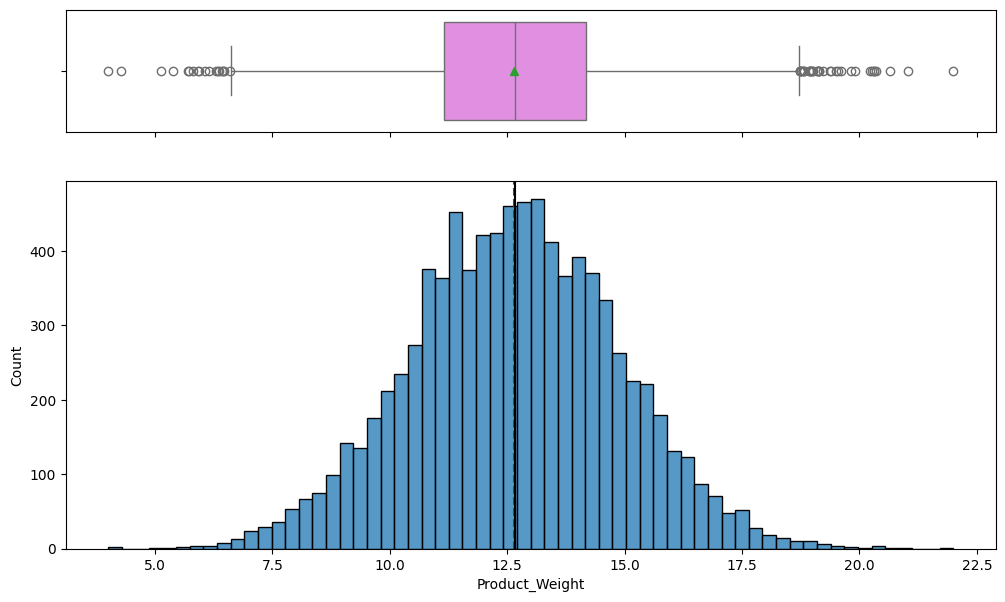

In [11]:
histogram_boxplot(data, "Product_Weight")

- Most product weights sit in a fairly compact range. The smaller values are kept because a light product is not automatically an incorrect record.

### Product_Allocated_Area

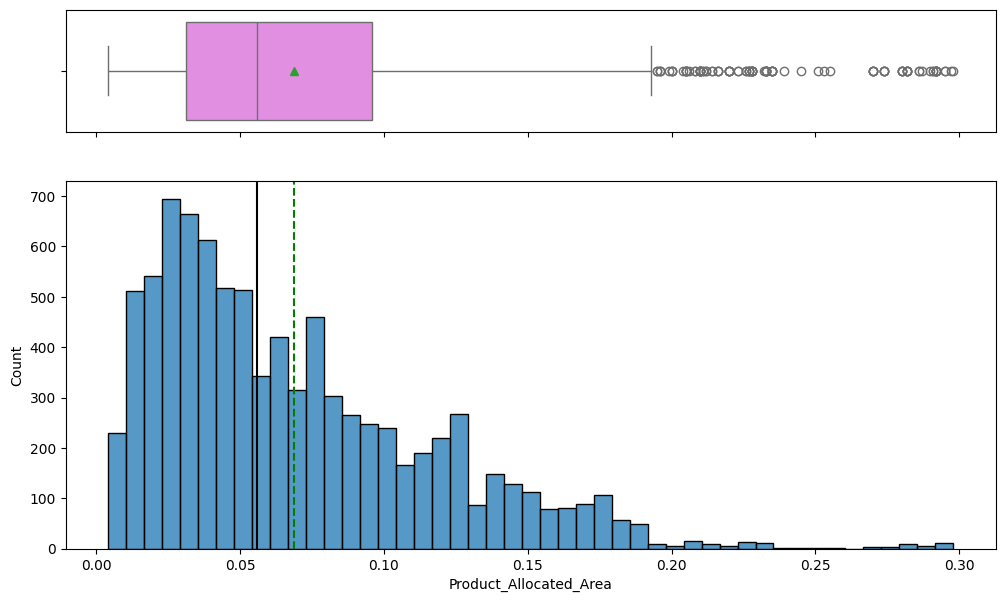

In [12]:
histogram_boxplot(data, "Product_Allocated_Area")

- Most products use a small share of the display area, with a longer right tail. A larger allocated area is plausible, so it is not removed only because it sits outside the boxplot whiskers.

### Product_MRP

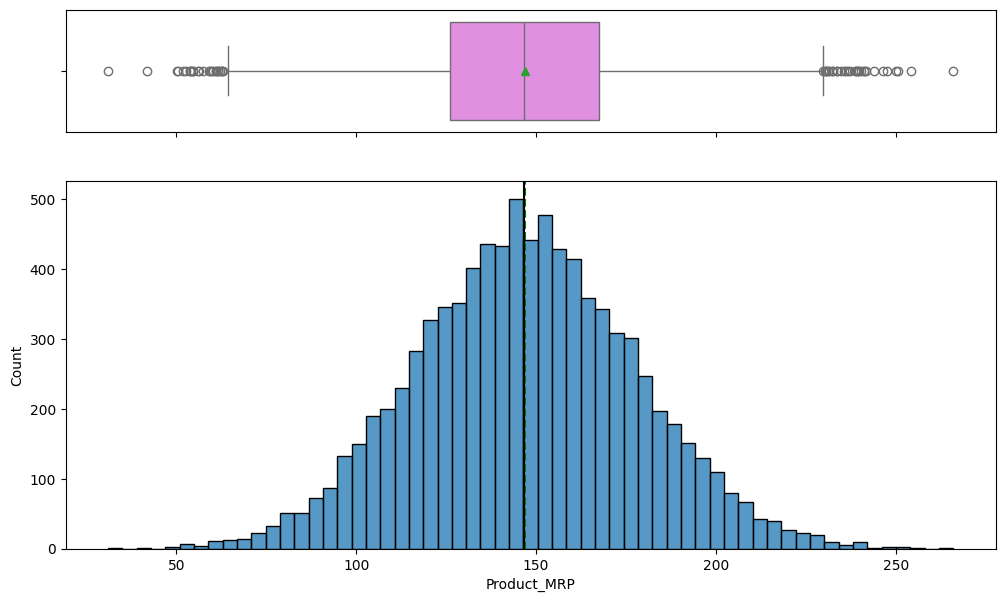

In [13]:
histogram_boxplot(data, "Product_MRP")

- Prices cover a wide range. The shape suggests several price groups rather than one single product-price level.

### Product_Store_Sales_Total

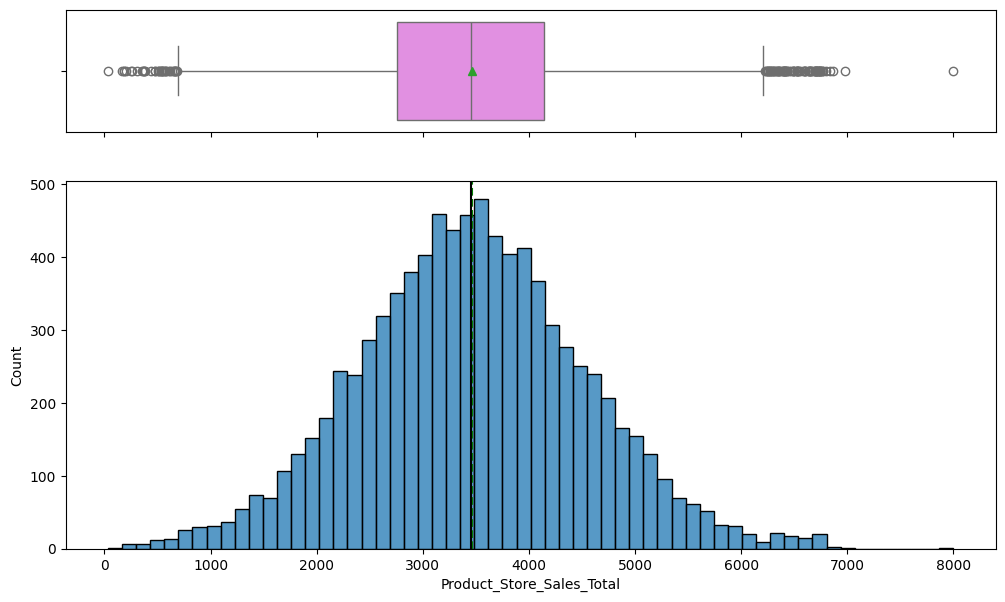

In [14]:
histogram_boxplot(data, "Product_Store_Sales_Total")

- Product-store revenue has a broad spread. The higher observations are kept because large revenue values may be valid and are important for inventory planning.

In [15]:
# function to create labeled barplots


def labeled_barplot(data, feature, perc=False, n=None):
    """
    Barplot with percentage at the top

    data: dataframe
    feature: dataframe column
    perc: whether to display percentages instead of count (default is False)
    n: displays the top n category levels (default is None, i.e., display all levels)
    """

    total = len(data[feature])  # length of the column
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 1, 5))
    else:
        plt.figure(figsize=(n + 1, 5))

    plt.xticks(rotation=90, fontsize=15)
    ax = sns.countplot(
        data=data,
        x=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n].sort_values(),
    )

    for p in ax.patches:
        if perc == True:
            label = "{:.1f}%".format(
                100 * p.get_height() / total
            )  # percentage of each class of the category
        else:
            label = p.get_height()  # count of each level of the category

        x = p.get_x() + p.get_width() / 2  # width of the plot
        y = p.get_height()  # height of the plot

        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )  # annotate the percentage

    plt.show()  # show the plot

### Product_Sugar_Content

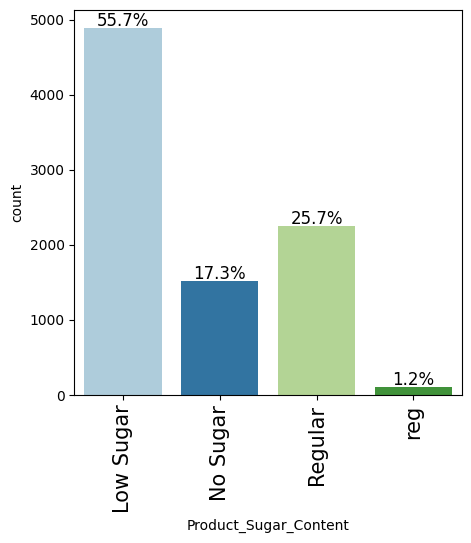

In [16]:
labeled_barplot(data, "Product_Sugar_Content", perc=True)

- Low Sugar is the largest group. The small reg group appears to mean Regular and will be combined with it during preprocessing.

### Product_Type

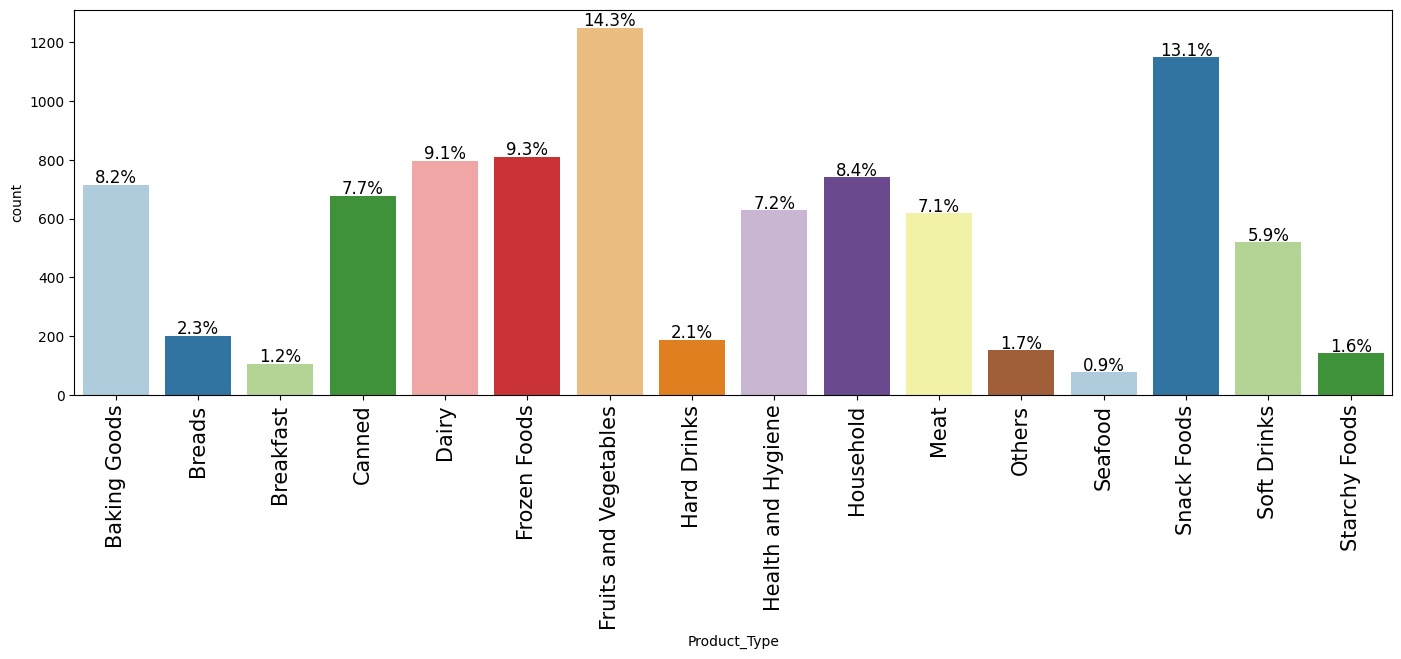

In [17]:
labeled_barplot(data, "Product_Type", perc=True)

- Fruits and Vegetables and Snack Foods have the largest representation. Breakfast, Starchy Foods, and Seafood have much smaller samples, so their results need more caution.

### Store_Id

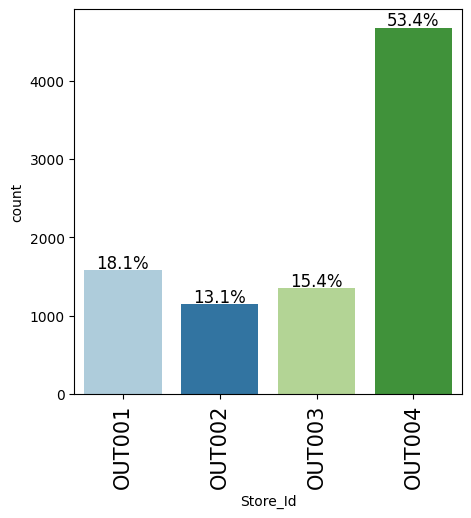

In [18]:
labeled_barplot(data, "Store_Id", perc=True)

- OUT004 supplies just over half of the rows. Its larger total revenue should therefore be considered alongside its number of product records.

### Store_Size

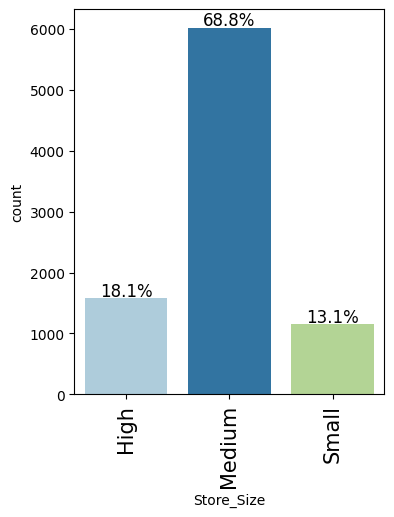

In [19]:
labeled_barplot(data, "Store_Size", perc=True)

- Medium stores make up most of the data. High and Small stores have less representation.

### Store_Location_City_Type

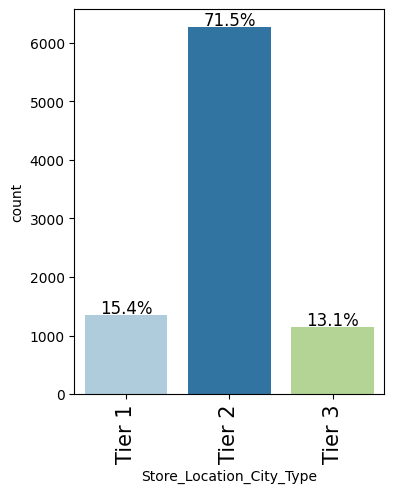

In [20]:
labeled_barplot(data, "Store_Location_City_Type", perc=True)

- Tier 2 locations account for most rows. The three city groups do not have equal coverage.

### Store_Type

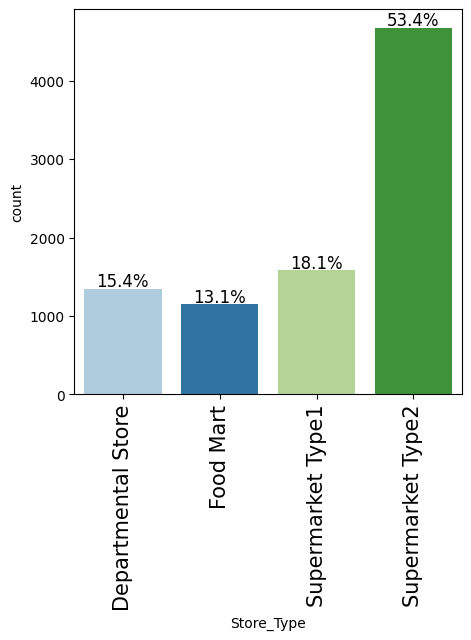

In [21]:
labeled_barplot(data, "Store_Type", perc=True)

- Supermarket Type2 is the largest group. Store type, size, and location are linked to the same four stores, so their individual effects are difficult to separate.

## Bivariate Analysis

### Numeric relationships

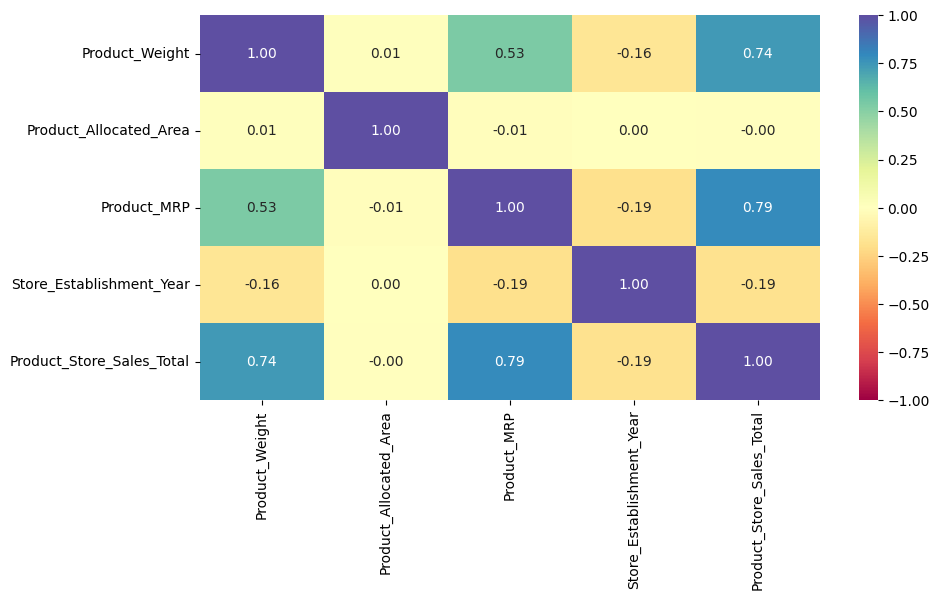

In [22]:
cols_list = data.select_dtypes(include=np.number).columns.tolist()

plt.figure(figsize=(10, 5))
sns.heatmap(
    data[cols_list].corr(), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral"
)
plt.show()

- Price has the strongest numeric relationship with revenue.
- A correlation describes association in this sample. It does not show that changing price alone will create the same change in revenue.

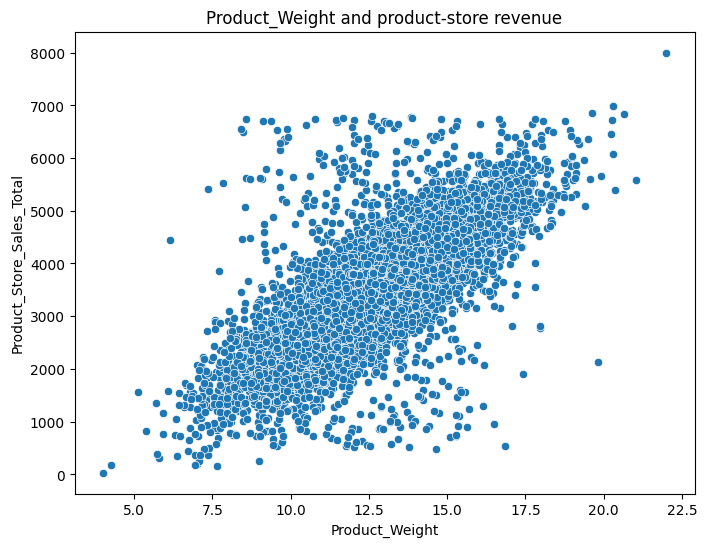

In [23]:
# Follow the supplied scatterplot pattern for each numeric feature
plt.figure(figsize=(8, 6))
sns.scatterplot(x=data["Product_Weight"], y=data["Product_Store_Sales_Total"])
plt.title("Product_Weight and product-store revenue")
plt.show()

- Heavier products tend to have higher revenue, although the relationship has considerable spread.

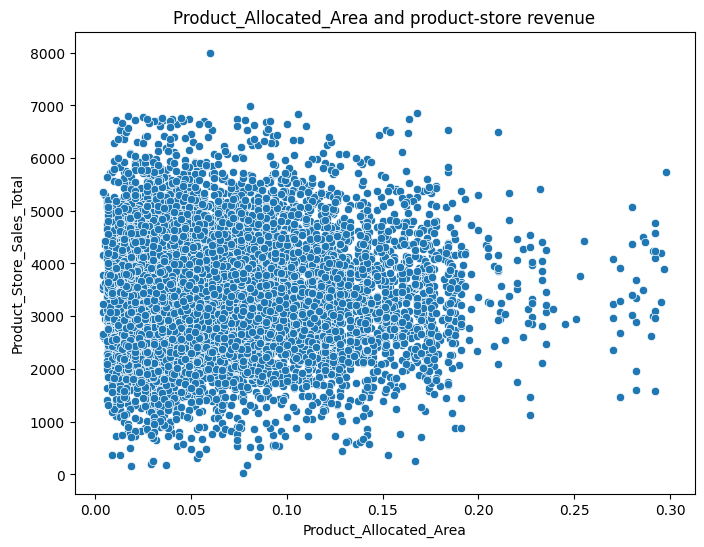

In [24]:
# Follow the supplied scatterplot pattern for each numeric feature
plt.figure(figsize=(8, 6))
sns.scatterplot(x=data["Product_Allocated_Area"], y=data["Product_Store_Sales_Total"])
plt.title("Product_Allocated_Area and product-store revenue")
plt.show()

- Display area alone does not show a strong clear relationship with revenue. The plot does not justify giving every product more shelf space.

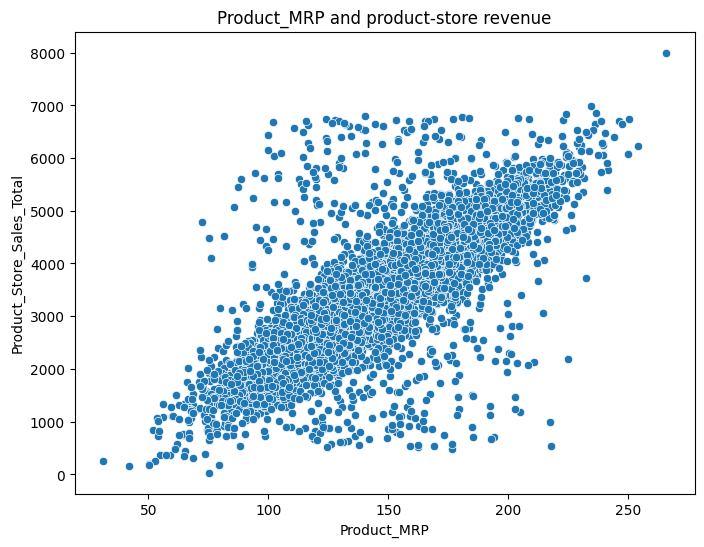

In [25]:
# Follow the supplied scatterplot pattern for each numeric feature
plt.figure(figsize=(8, 6))
sns.scatterplot(x=data["Product_MRP"], y=data["Product_Store_Sales_Total"])
plt.title("Product_MRP and product-store revenue")
plt.show()

- Revenue generally rises with price, but the separate bands suggest that store characteristics also matter.

### Revenue by product and store

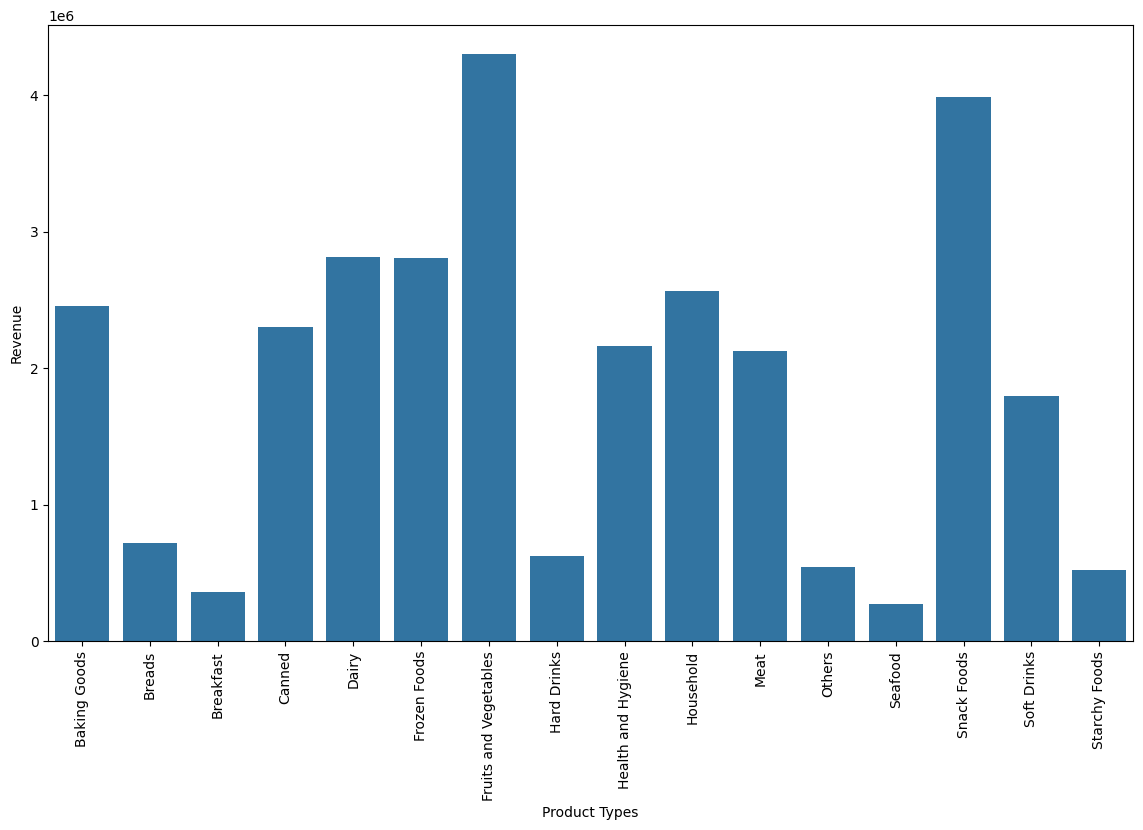

In [26]:
df_revenue1 = data.groupby(["Product_Type"], as_index=False)[
    "Product_Store_Sales_Total"
].sum()
plt.figure(figsize=[14, 8])
plt.xticks(rotation=90)
a = sns.barplot(x=df_revenue1.Product_Type, y=df_revenue1.Product_Store_Sales_Total)
a.set_xlabel("Product Types")
a.set_ylabel("Revenue")
plt.show()

- Fruits and Vegetables and Snack Foods lead total revenue. These are large groups in the sample, so totals should not be read as revenue per product or profit.

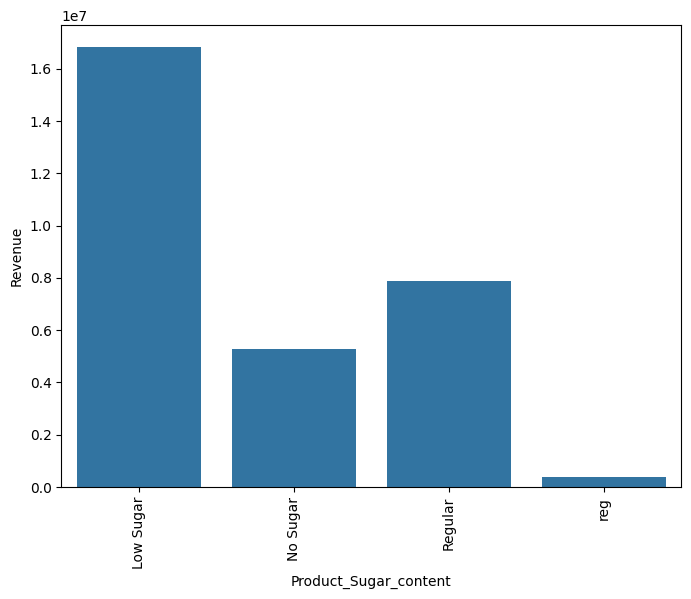

In [27]:
df_revenue2 = data.groupby(["Product_Sugar_Content"], as_index=False)[
    "Product_Store_Sales_Total"
].sum() 
plt.figure(figsize=[8, 6])
plt.xticks(rotation=90)
b = sns.barplot(
    x=df_revenue2.Product_Sugar_Content, y=df_revenue2.Product_Store_Sales_Total
)
b.set_xlabel("Product_Sugar_content")
b.set_ylabel("Revenue")
plt.show()

- Low Sugar products contribute the most revenue. The separate reg label needs to be combined with Regular before making a final sugar-content comparison.

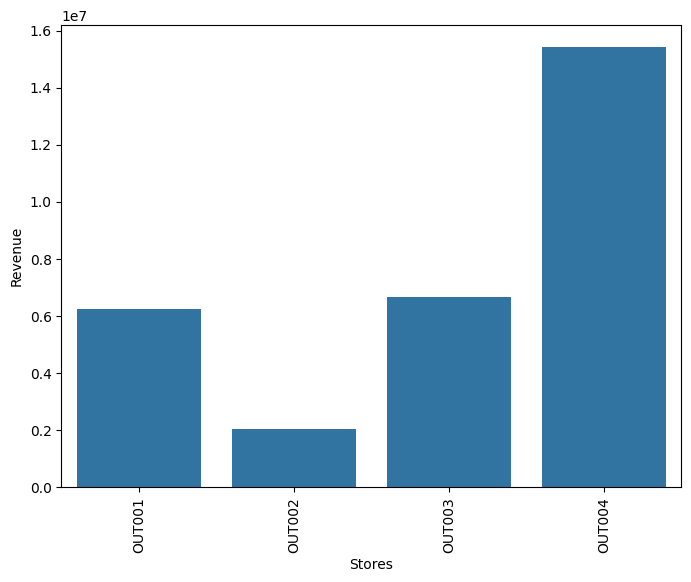

In [28]:
df_store_revenue = data.groupby(["Store_Id"], as_index=False)[
    "Product_Store_Sales_Total"
].sum()
plt.figure(figsize=[8, 6])
plt.xticks(rotation=90)
r = sns.barplot(
    x=df_store_revenue.Store_Id, y=df_store_revenue.Product_Store_Sales_Total
)
r.set_xlabel("Stores")
r.set_ylabel("Revenue")
plt.show()

- OUT004 has the highest total revenue, followed by OUT003 and OUT001. OUT002 has the lowest total, but it is also the smallest store in this sample.

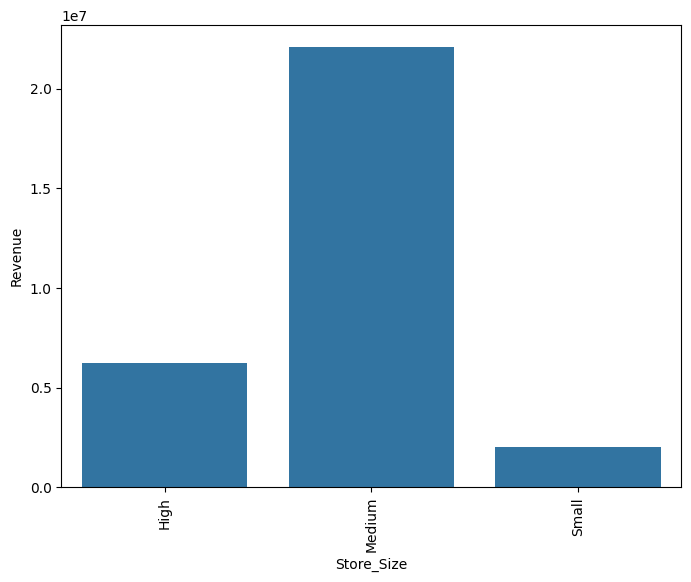

In [29]:
df_revenue3 = data.groupby(["Store_Size"], as_index=False)[
    "Product_Store_Sales_Total"
].sum()
plt.figure(figsize=[8, 6])
plt.xticks(rotation=90)
c = sns.barplot(x=df_revenue3.Store_Size, y=df_revenue3.Product_Store_Sales_Total)
c.set_xlabel("Store_Size")
c.set_ylabel("Revenue")
plt.show()

- Medium stores generate the highest total revenue. There are also more records from Medium stores, which affects the comparison.

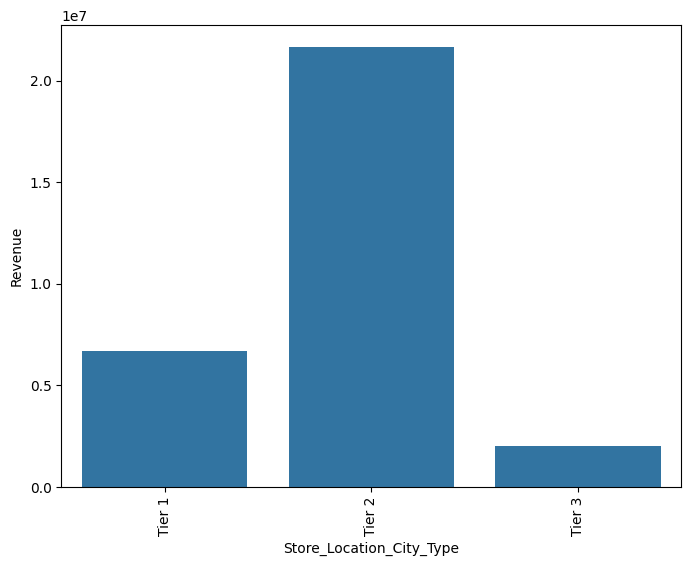

In [30]:
df_revenue4 = data.groupby(["Store_Location_City_Type"], as_index=False)[
    "Product_Store_Sales_Total"
].sum()
plt.figure(figsize=[8, 6])
plt.xticks(rotation=90)
d = sns.barplot(
    x=df_revenue4.Store_Location_City_Type, y=df_revenue4.Product_Store_Sales_Total
)
d.set_xlabel("Store_Location_City_Type")
d.set_ylabel("Revenue")
plt.show()

- Tier 2 locations contribute the most revenue in total. The available stores and their sizes differ by tier, so this does not prove a general advantage for every Tier 2 location.

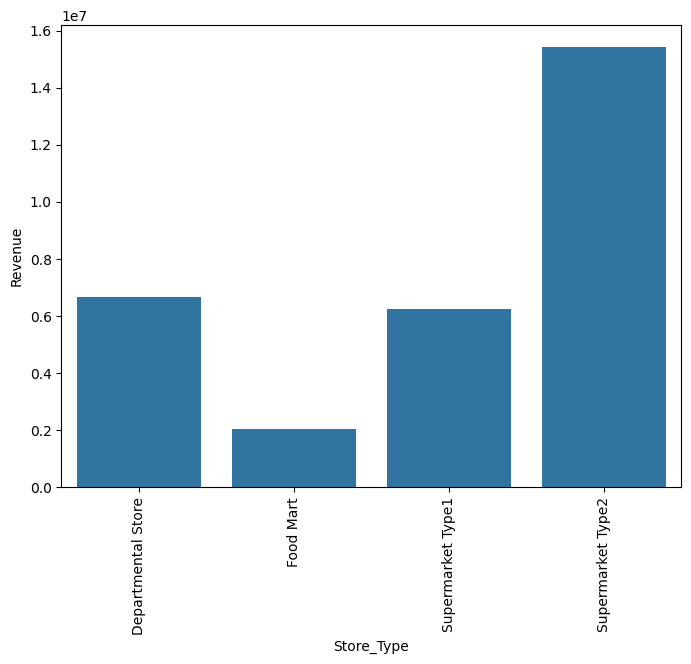

In [31]:
df_revenue5 = data.groupby(["Store_Type"], as_index=False)[
    "Product_Store_Sales_Total"
].sum()
plt.figure(figsize=[8, 6])
plt.xticks(rotation=90)
e = sns.barplot(x=df_revenue5.Store_Type, y=df_revenue5.Product_Store_Sales_Total)
e.set_xlabel("Store_Type")
e.set_ylabel("Revenue")
plt.show()

- Supermarket Type2 produces the most total revenue. Departmental Store has fewer rows, so the next table also compares revenue per record.

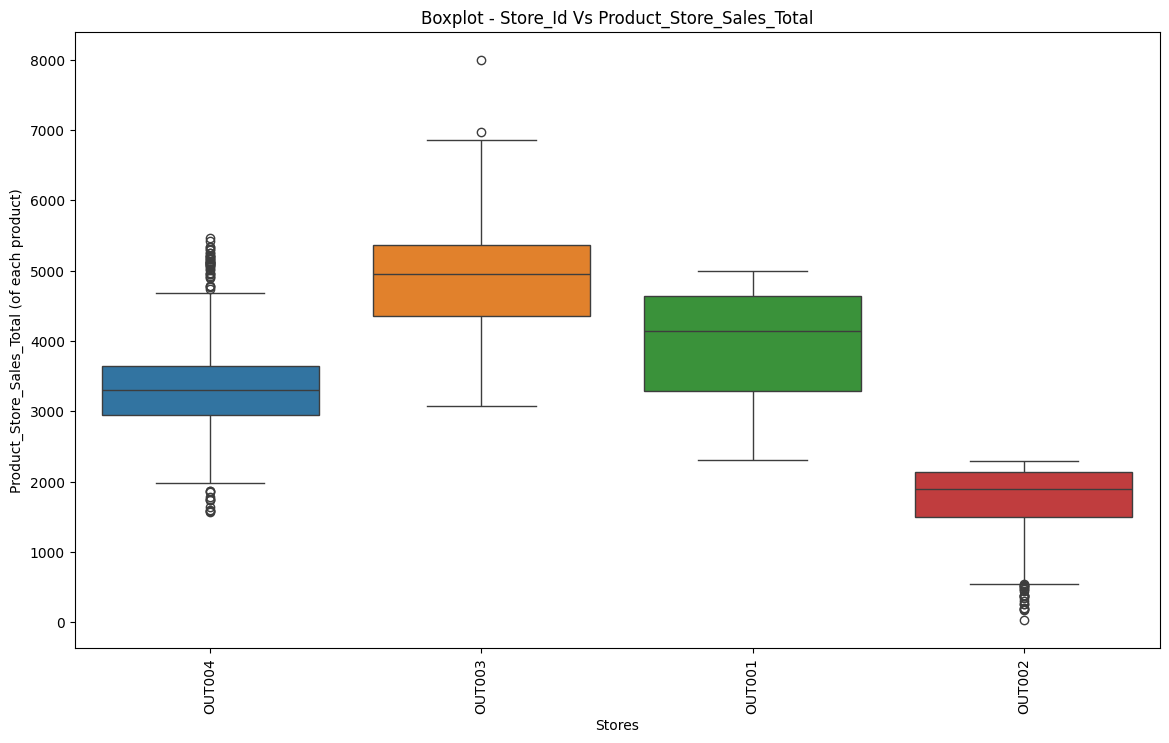

In [32]:
plt.figure(figsize=[14, 8])
sns.boxplot(data=data, x="Store_Id", y="Product_Store_Sales_Total", hue = "Store_Id")
plt.xticks(rotation=90)
plt.title("Boxplot - Store_Id Vs Product_Store_Sales_Total")
plt.xlabel("Stores")
plt.ylabel("Product_Store_Sales_Total (of each product)")
plt.show()

- The store revenue distributions differ clearly. A single overall average would miss these differences.

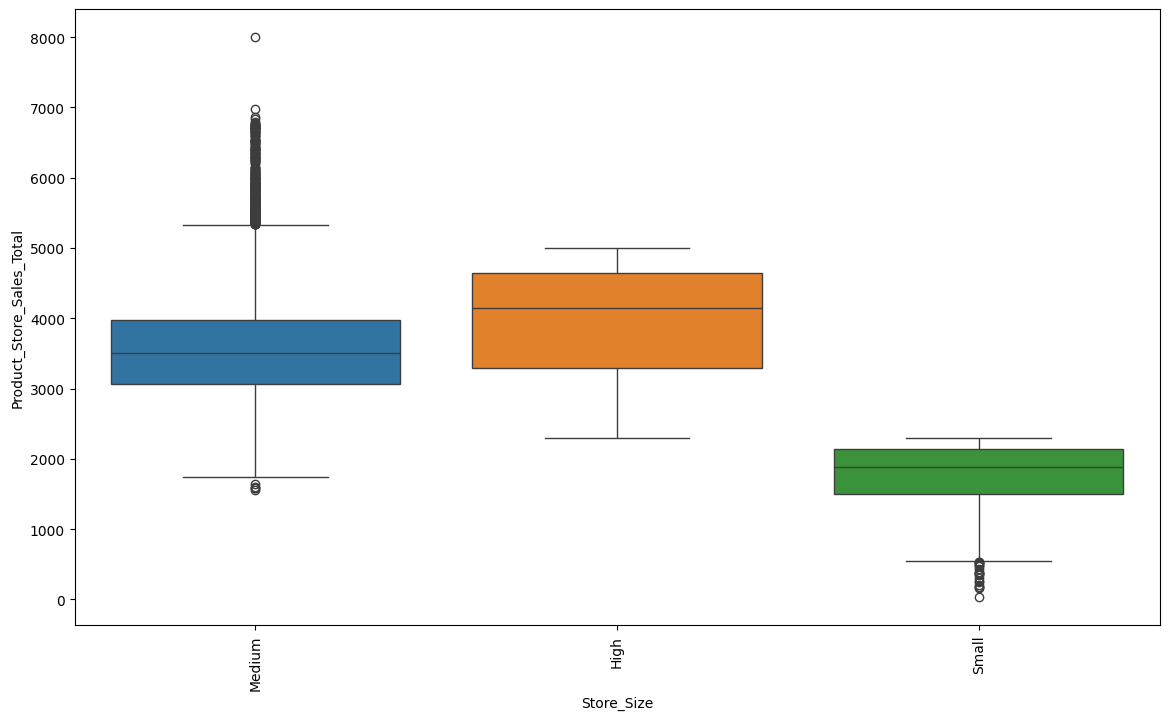

In [33]:
plt.figure(figsize=[14, 8])
sns.boxplot(data = data, x = "Store_Size", y = "Product_Store_Sales_Total", hue = "Store_Size")
plt.xticks(rotation=90)
plt.show()

- Store sizes have different revenue distributions, but size is tied to the stores in this file. It should not be treated as an isolated cause.

### Product relationships

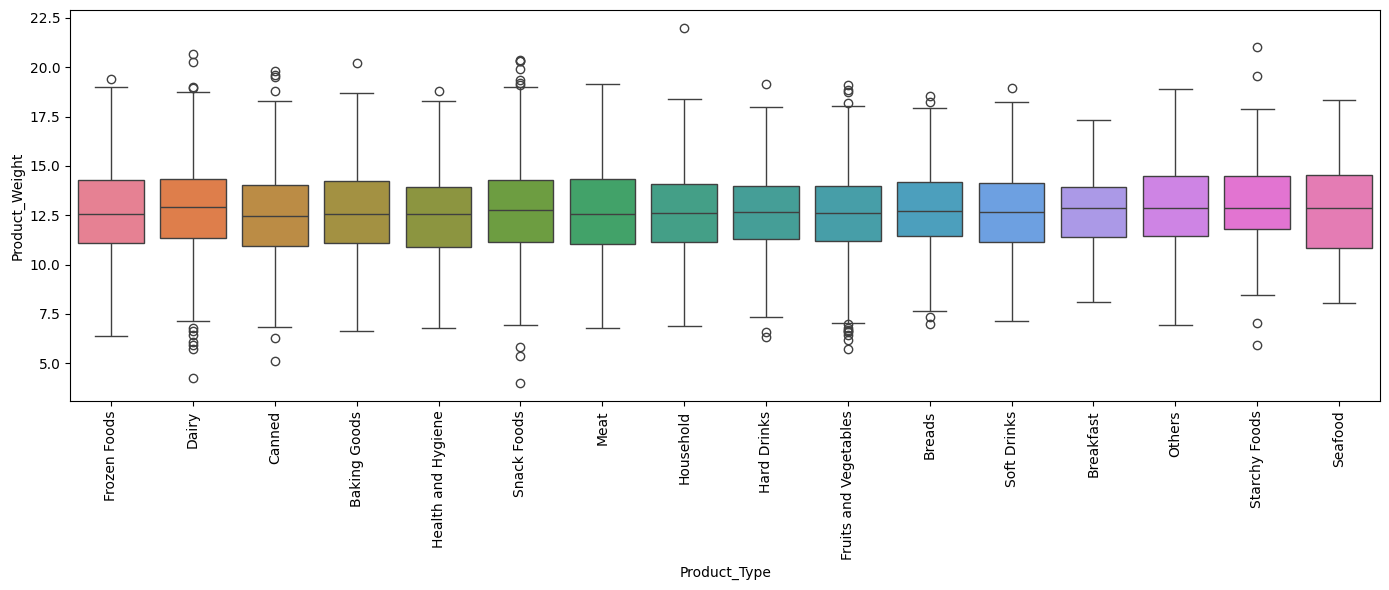

In [34]:
# Use the supplied boxplot structure with the completed column names
plt.figure(figsize=(14, 6))
sns.boxplot(data=data, x="Product_Type", y="Product_Weight", hue="Product_Type")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

- Weight varies by product category, which is expected when food, drinks, and household goods are mixed together.

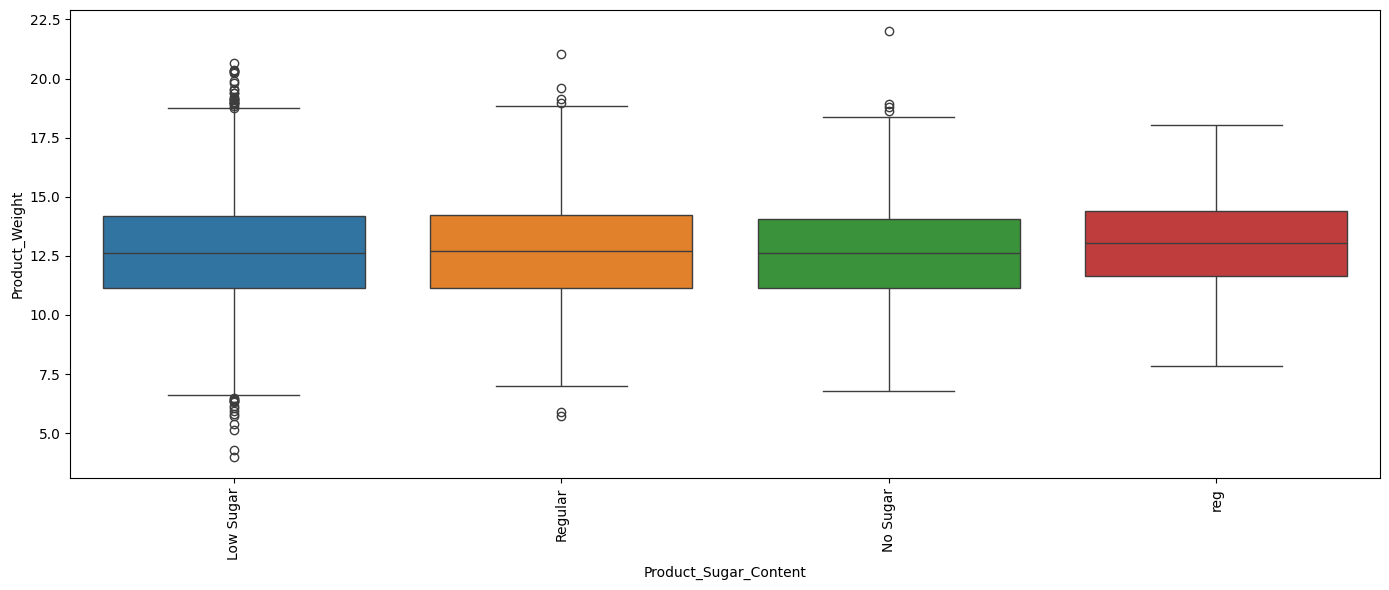

In [35]:
# Use the supplied boxplot structure with the completed column names
plt.figure(figsize=(14, 6))
sns.boxplot(data=data, x="Product_Sugar_Content", y="Product_Weight", hue="Product_Sugar_Content")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

- Sugar groups have overlapping weight ranges. Weight alone cannot identify the sugar category.

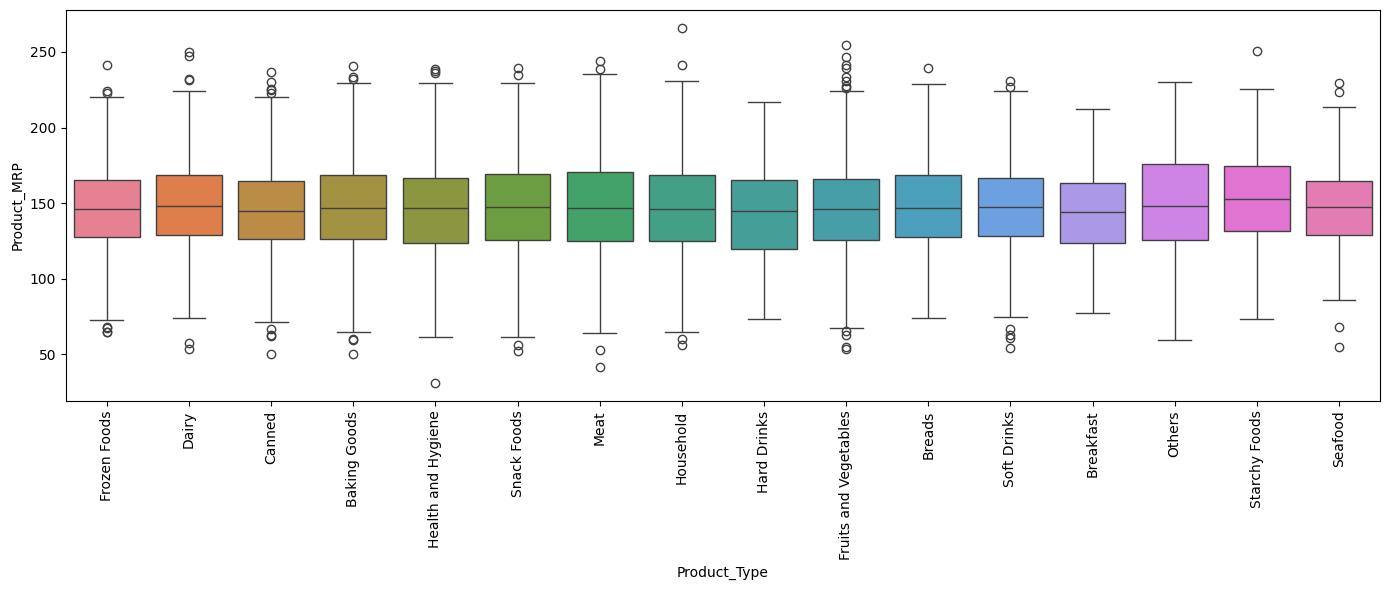

In [36]:
# Use the supplied boxplot structure with the completed column names
plt.figure(figsize=(14, 6))
sns.boxplot(data=data, x="Product_Type", y="Product_MRP", hue="Product_Type")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

- Prices vary by product category. Products should be compared within suitable categories before a pricing decision is made.

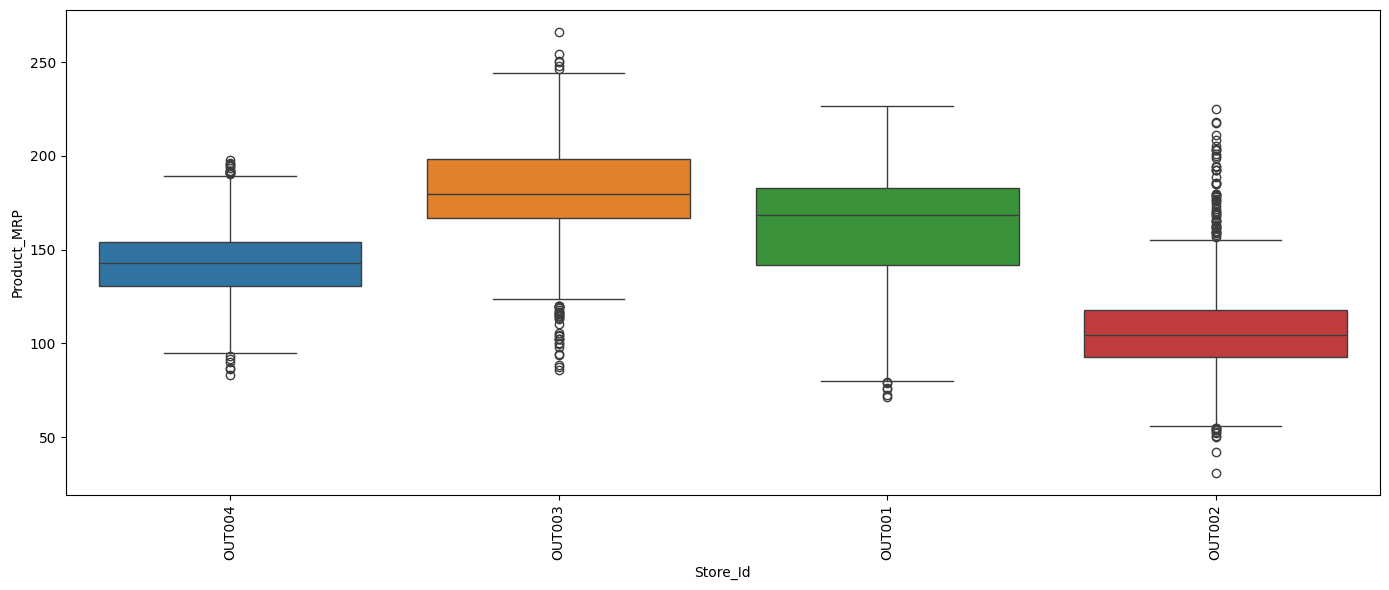

In [37]:
# Use the supplied boxplot structure with the completed column names
plt.figure(figsize=(14, 6))
sns.boxplot(data=data, x="Store_Id", y="Product_MRP", hue="Store_Id")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

- Stores carry different price ranges, which helps explain some of the difference in revenue between them.

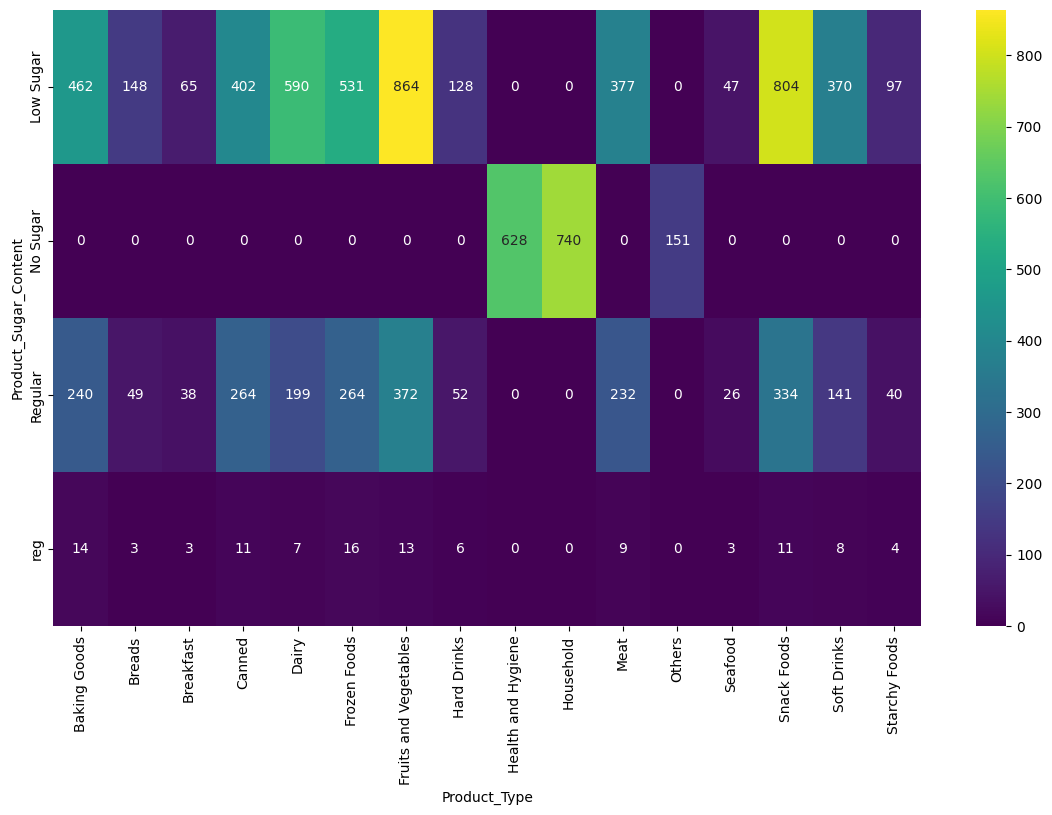

In [38]:
plt.figure(figsize=(14, 8))
sns.heatmap(
    pd.crosstab(data["Product_Sugar_Content"], data["Product_Type"]),
    annot=True,
    fmt="g",
    cmap="viridis",
)
plt.ylabel("Product_Sugar_Content")
plt.xlabel("Product_Type")
plt.show()

- Some product categories are concentrated in one sugar group. Several categorical features therefore carry overlapping information.

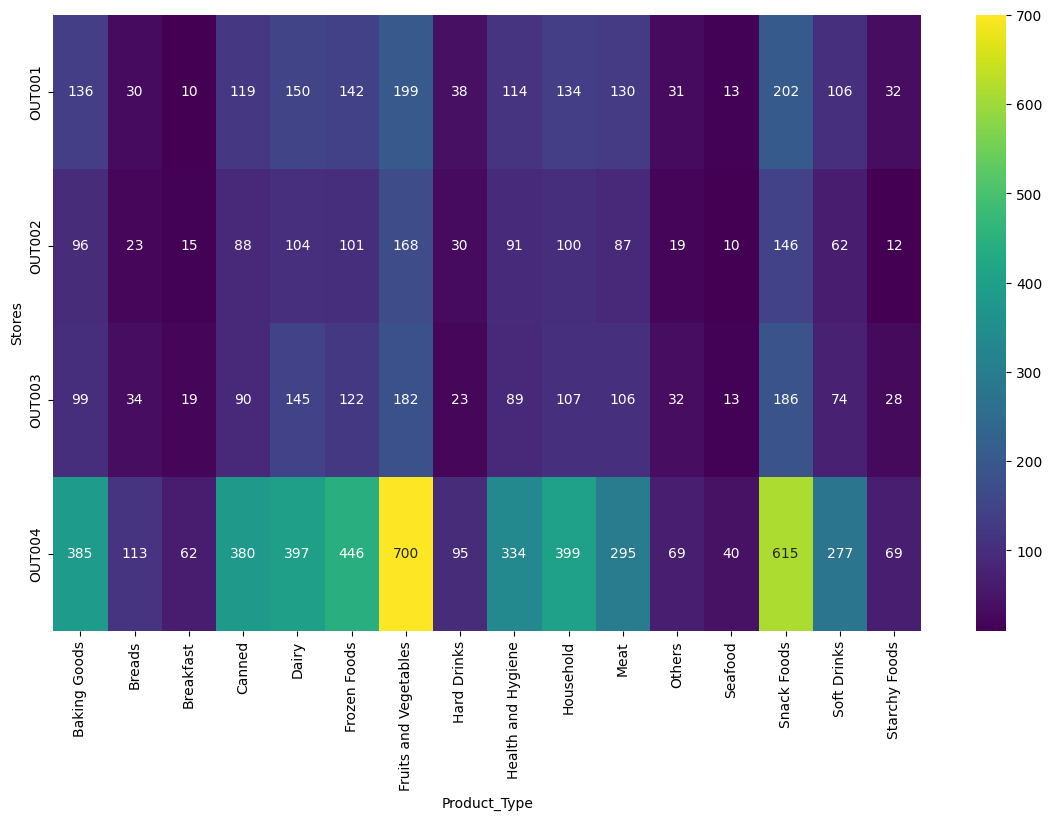

In [39]:
plt.figure(figsize=(14, 8))
sns.heatmap(
    pd.crosstab(data["Store_Id"], data["Product_Type"]),
    annot=True,
    fmt="g",
    cmap="viridis",
)
plt.ylabel("Stores")
plt.xlabel("Product_Type")
plt.show()

- OUT004 has more records in most product categories. The larger coverage is an important part of its high revenue total.

### Store comparison

In [40]:
# Add revenue per record and share so the supplied totals have context
store_summary = kart.groupby("Store_Id").agg(
    Store_Type=("Store_Type", "first"),
    City_Tier=("Store_Location_City_Type", "first"),
    Store_Size=("Store_Size", "first"),
    Records=("Product_Id", "size"),
    Total_Revenue=("Product_Store_Sales_Total", "sum"),
    Mean_Revenue=("Product_Store_Sales_Total", "mean"),
)
store_summary["Revenue_Share_Percent"] = 100 * store_summary.Total_Revenue / store_summary.Total_Revenue.sum()
display(store_summary.round(2))

,Store_Type,City_Tier,Store_Size,Records,Total_Revenue,Mean_Revenue,Revenue_Share_Percent
Store_Id,,,,,,,
OUT001,Supermarket Type1,Tier 2,High,1586,6223113.18,3923.78,20.50
OUT002,Food Mart,Tier 3,Small,1152,2030909.72,1762.94,6.69
OUT003,Departmental Store,Tier 1,Medium,1349,6673457.57,4946.97,21.98
OUT004,Supermarket Type2,Tier 2,Medium,4676,15427583.43,3299.31,50.82


- The detailed store summaries in the low-code notebook are combined here in one comparison table. Revenue per record and percentage share are added to make the totals easier to interpret.
- OUT004 leads total revenue, while OUT003 has the highest revenue per record. These are different measures and support different planning decisions.
- There are only four stores. Store age, size, type, and city tier describe these same four locations, so the file cannot establish what will work in every new location.
- OUT004 contributes about 50.8% of observed revenue across 53.4% of the records. OUT003 averages about 4,946.97 revenue units per record, compared with 3,299.31 for OUT004.

#### OUT001

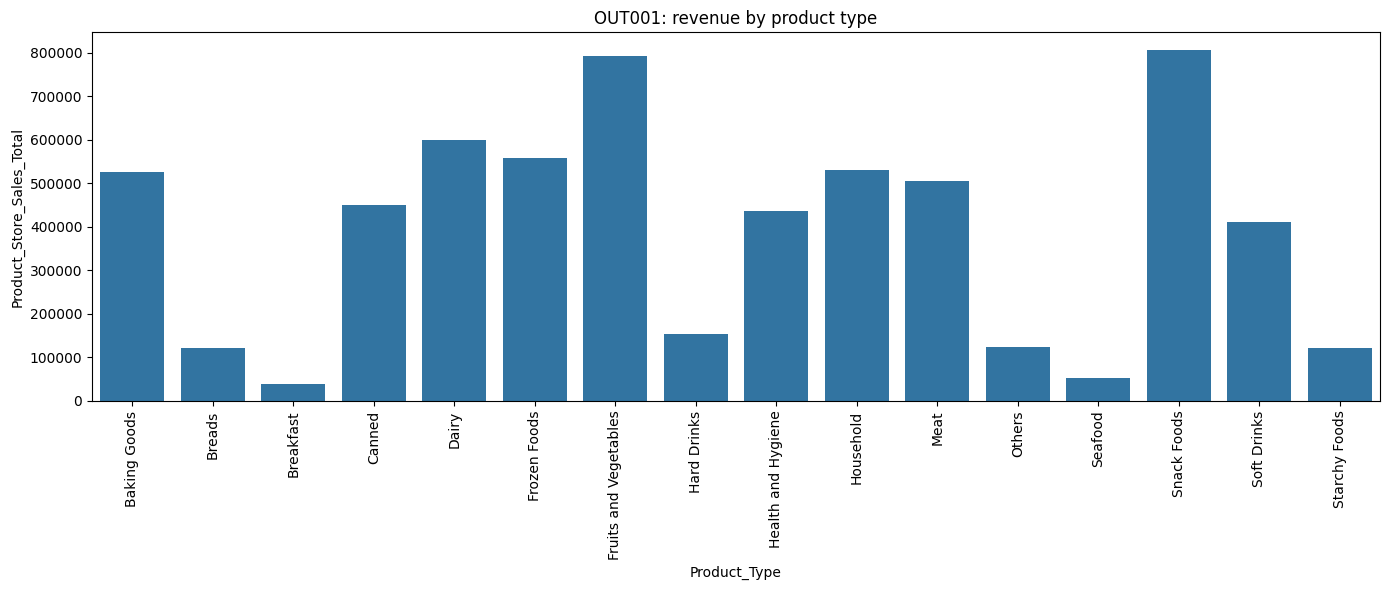

In [41]:
# Follow the low-code store-by-product revenue breakdown
df_OUT001 = (
    data.loc[data["Store_Id"] == "OUT001"]
    .groupby(["Product_Type"], as_index=False)["Product_Store_Sales_Total"].sum()
)
plt.figure(figsize=(14, 6))
sns.barplot(x=df_OUT001.Product_Type, y=df_OUT001.Product_Store_Sales_Total)
plt.xticks(rotation=90)
plt.title("OUT001: revenue by product type")
plt.tight_layout()
plt.show()

- Fruits and Vegetables and Snack Foods are the main revenue categories for OUT001. Both deserve close stock-availability checks.

#### OUT002

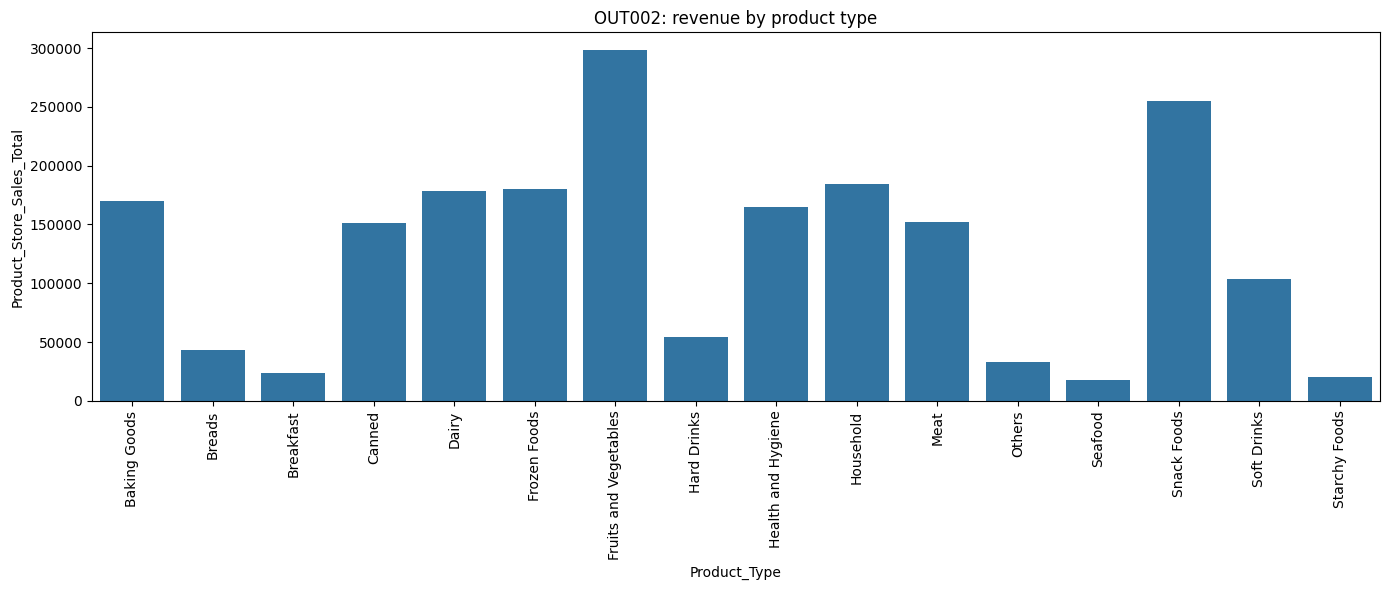

In [42]:
# Follow the low-code store-by-product revenue breakdown
df_OUT002 = (
    data.loc[data["Store_Id"] == "OUT002"]
    .groupby(["Product_Type"], as_index=False)["Product_Store_Sales_Total"].sum()
)
plt.figure(figsize=(14, 6))
sns.barplot(x=df_OUT002.Product_Type, y=df_OUT002.Product_Store_Sales_Total)
plt.xticks(rotation=90)
plt.title("OUT002: revenue by product type")
plt.tight_layout()
plt.show()

- Fruits and Vegetables leads revenue for OUT002, followed by Snack Foods. Lower total revenue should be assessed alongside the store's smaller size and product coverage.

#### OUT003

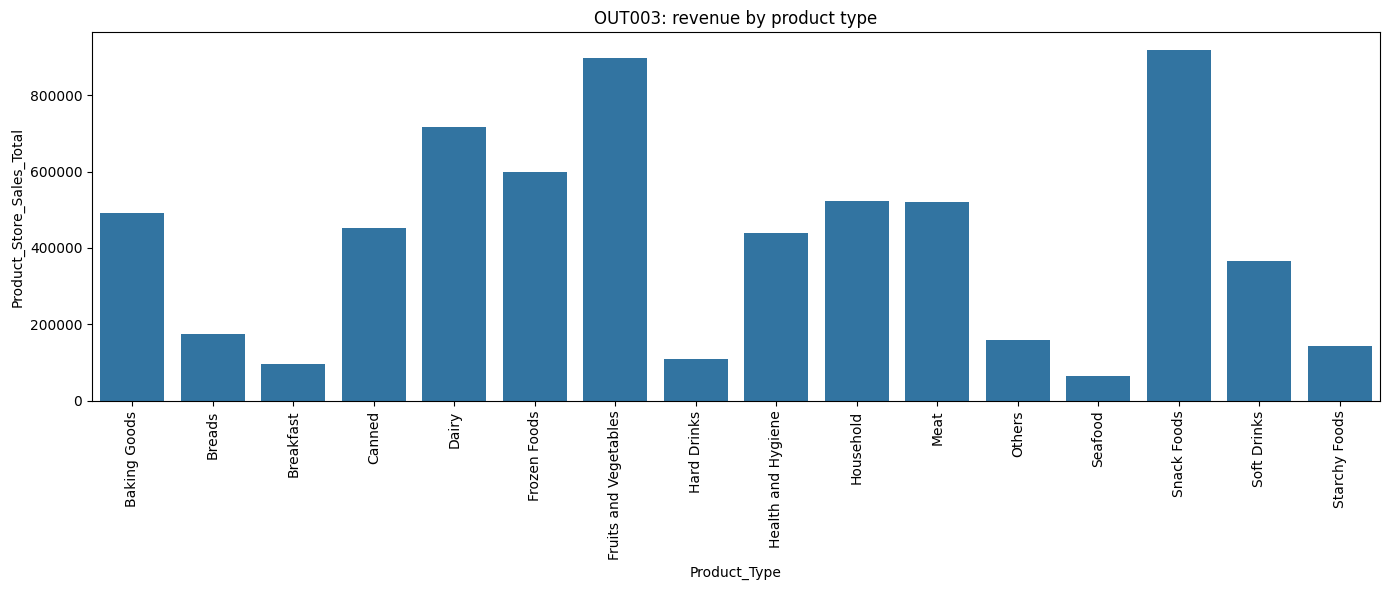

In [43]:
# Follow the low-code store-by-product revenue breakdown
df_OUT003 = (
    data.loc[data["Store_Id"] == "OUT003"]
    .groupby(["Product_Type"], as_index=False)["Product_Store_Sales_Total"].sum()
)
plt.figure(figsize=(14, 6))
sns.barplot(x=df_OUT003.Product_Type, y=df_OUT003.Product_Store_Sales_Total)
plt.xticks(rotation=90)
plt.title("OUT003: revenue by product type")
plt.tight_layout()
plt.show()

- Snack Foods and Fruits and Vegetables lead OUT003's revenue. Its higher revenue per record makes it useful for studying product mix and price differences.

#### OUT004

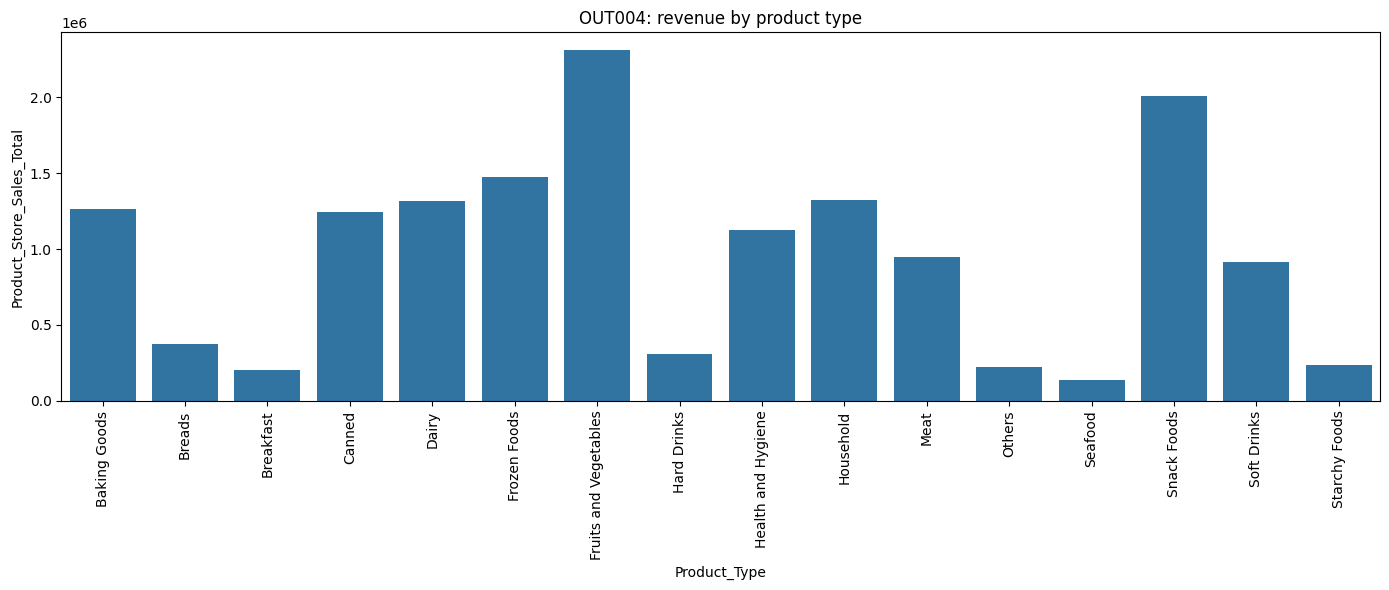

In [44]:
# Follow the low-code store-by-product revenue breakdown
df_OUT004 = (
    data.loc[data["Store_Id"] == "OUT004"]
    .groupby(["Product_Type"], as_index=False)["Product_Store_Sales_Total"].sum()
)
plt.figure(figsize=(14, 6))
sns.barplot(x=df_OUT004.Product_Type, y=df_OUT004.Product_Store_Sales_Total)
plt.xticks(rotation=90)
plt.title("OUT004: revenue by product type")
plt.tight_layout()
plt.show()

- Fruits and Vegetables and Snack Foods also lead OUT004. This store needs the largest overall stock-planning attention because it contributes the most observed revenue.

# **Data Preprocessing**

## Clean sugar labels

In [45]:
# Assign the cleaned column directly instead of using chained inplace replacement
data["Product_Sugar_Content"] = data["Product_Sugar_Content"].replace({"reg": "Regular"})
data["Product_Sugar_Content"].value_counts()

Product_Sugar_Content
Low Sugar    4885
Regular      2359
No Sugar     1519
Name: count, dtype: int64

- The reg values are combined with Regular because they describe the same sugar level.
- The supplied inplace replacement is changed to direct column assignment to avoid Pandas chained-assignment behavior.

## Product prefix

In [46]:
## extracting the first two characters from the Product_Id column and storing it in another column
data["Product_Id_char"] = data["Product_Id"].str[:2]
data.head()

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total,Product_Id_char
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40,FD
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02,FD
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16,FD
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18,FD
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36,NC


- The first two letters of Product_Id provide a broad product group. This preserves a useful part of the identifier without treating every individual product code as a category.

In [47]:
# Display the same three prefix checks together
for prefix in data["Product_Id_char"].unique():
    print(prefix, ":", ", ".join(data.loc[data.Product_Id_char == prefix, "Product_Type"].unique()))

FD : Frozen Foods, Dairy, Canned, Baking Goods, Snack Foods, Meat, Fruits and Vegetables, Breads, Breakfast, Starchy Foods, Seafood
NC : Health and Hygiene, Household, Others
DR : Hard Drinks, Soft Drinks


- FD covers food, DR covers drinks, and NC covers non-consumable categories.
- The three separate low-code checks are displayed in one loop so the mapping can be read together.

## Store age

In [48]:
# Outlet Age
data["Store_Age_Years"] = 2025 - data.Store_Establishment_Year

- Store age uses 2025 as in the supplied notebook and batch data. Keeping that reference year fixed gives training and prediction inputs the same meaning.
- This variable may capture differences among the four stores; it does not prove that age itself raises revenue.

## Perishable and non-perishable products

In [49]:
perishables = [
    "Dairy",
    "Meat",
    "Fruits and Vegetables",
    "Breakfast",
    "Breads",
    "Seafood",
]

In [50]:
def change(x):
    if x in perishables:
        return "Perishables"
    else:
        return "Non Perishables"

In [51]:
data['Product_Type_Category'] = data['Product_Type'].apply(change)

- The product categories are grouped into Perishables and Non Perishables using the list supplied in the low-code notebook.
- The same names are used in the deployment payload and batch CSV, so the model sees consistent categories.

## Outlier check

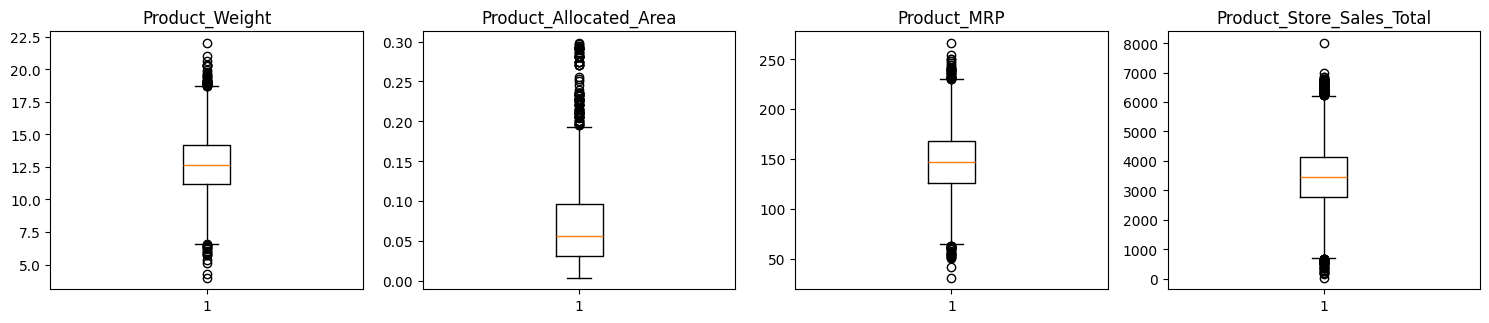

In [52]:
# outlier detection using boxplot
numeric_columns = data.select_dtypes(include=np.number).columns.tolist()
numeric_columns.remove("Store_Establishment_Year")
numeric_columns.remove("Store_Age_Years")


plt.figure(figsize=(15, 12))

for i, variable in enumerate(numeric_columns):
    plt.subplot(4, 4, i + 1)
    plt.boxplot(data[variable], whis=1.5)
    plt.tight_layout()
    plt.title(variable)

plt.show()

- The boxplots show some values beyond the whiskers. These are kept because the data provides no evidence that they are entry errors.
- Tree-based models can handle uneven distributions, and removing high-revenue products would discard an important part of the business problem.

## Prepare features and target

In [53]:
data = data.drop(["Product_Id", "Product_Type", "Store_Id", "Store_Establishment_Year"], axis=1)

- The original IDs and establishment year are removed after creating product prefix, category, and store age.
- This follows the low-code feature set and leaves the ten features expected by the supplied deployment examples.

In [54]:
# Separating features and the target column
X = data.drop("Product_Store_Sales_Total", axis=1)
y = data["Product_Store_Sales_Total"]

In [55]:
# Splitting the data into train and test sets in 70:30 ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1, shuffle=True
)

In [56]:
X_train.shape, X_test.shape

((6134, 10), (2629, 10))

- The 70:30 split with random_state set to 1 follows the course notebook: 6,134 training rows and 2,629 test rows.
- All preprocessing is fitted inside the training pipeline. Hyperparameter selection uses training cross-validation, while the test set is reserved for the final comparison.
- This random split checks new rows from the available stores. It is not a test on a future quarter or on entirely new stores.

In [57]:
categorical_features = data.select_dtypes(include=['object', 'category']).columns.tolist()
categorical_features

['Product_Sugar_Content',
 'Store_Size',
 'Store_Location_City_Type',
 'Store_Type',
 'Product_Id_char',
 'Product_Type_Category']

In [58]:
# Keep numeric columns; the supplied default would otherwise drop them
preprocessor = make_column_transformer(
    (Pipeline([("encoder", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
    remainder="passthrough",
)
preprocessor

ColumnTransformer(remainder='passthrough',
                  transformers=[('pipeline',
                                 Pipeline(steps=[('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Product_Sugar_Content', 'Store_Size',
                                  'Store_Location_City_Type', 'Store_Type',
                                  'Product_Id_char',
                                  'Product_Type_Category'])])

- The categorical pipeline follows the supplied OneHotEncoder structure.
- The remainder setting is changed to passthrough so price, weight, display area, and store age are retained. Without this change, the original setup silently drops all four numeric features.
- Unknown categories can be processed, but that does not mean their estimates have been validated. The API reports them for review.

# **Model Building**

## Define functions for Model Evaluation

In [59]:
# Count encoded columns when calculating the adjusted R-squared diagnostic
def adj_r2_score(predictors, targets, predictions):
    r2 = r2_score(targets, predictions)
    n, k = predictors.shape
    return 1 - ((1 - r2) * (n - 1) / (n - k - 1))


def model_performance_regression(model, predictors, target):
    """Compare prediction errors and explained variation on one dataset."""
    pred = model.predict(predictors)
    encoded_predictors = model[:-1].transform(predictors)
    return pd.DataFrame({
        "RMSE": [np.sqrt(mean_squared_error(target, pred))],
        "MAE": [mean_absolute_error(target, pred)],
        "R-squared": [r2_score(target, pred)],
        "Adj. R-squared": [adj_r2_score(encoded_predictors, target, pred)],
        "MAPE": [mean_absolute_percentage_error(target, pred)],
    })

- RMSE gives more weight to large errors, MAE shows the average absolute error, and MAPE is a fraction that can be multiplied by 100 for a percentage.
- The adjusted R-squared calculation is changed to count the encoded columns rather than the original ten columns. For these tree models it is only a descriptive diagnostic; RMSE and validation performance drive the selection.

## Mean-only baseline

In [60]:
# Add a simple benchmark to show what the fitted models need to improve on
mean_model = make_pipeline(clone(preprocessor), DummyRegressor(strategy="mean"))
mean_model.fit(X_train, y_train)
display(model_performance_regression(mean_model, X_test, y_test))

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,1069.937796,844.670452,-0.000363,-0.008808,0.361862


- This added benchmark predicts the training average for every row. The two selected models need to improve on it to justify using the product and store features.
- Its test RMSE is 1,069.94, compared with 290.79 for the selected model. The product and store features provide a large improvement over predicting the average.

## Random Forest

In [61]:
# Use a separate copy of the supplied preprocessing pipeline for each model
rf_estimator = make_pipeline(clone(preprocessor), RandomForestRegressor(random_state=1, n_jobs=2))
rf_estimator.fit(X_train, y_train)
rf_model_train_perf = model_performance_regression(rf_estimator, X_train, y_train)
rf_model_test_perf = model_performance_regression(rf_estimator, X_test, y_test)
display(pd.concat([rf_model_train_perf, rf_model_test_perf], keys=["Train", "Test"]))

,,RMSE,MAE,R-squared,Adj. R-squared,MAPE
Train,0,104.566026,39.946068,0.990337,0.990302,0.014121
Test,0,295.940703,112.705907,0.923467,0.922821,0.050206


- Random Forest is the first of the two required models. Its training error is expected to be lower than its test error because the trees can fit detailed patterns in the training rows.
- Each model gets its own copied preprocessor so fitting the next model cannot alter the previous model's fitted encoder. The worker count is limited to two for this machine.
- Training RMSE is 104.57 and test RMSE is 295.94, with test R-squared of 0.9235. The much smaller training error suggests some overfitting, which tuning should try to reduce.

## XGBoost

In [62]:
# Keep the course model and seed, with the same two-worker limit
xgb_estimator = make_pipeline(clone(preprocessor), XGBRegressor(random_state=1, n_jobs=2))
xgb_estimator.fit(X_train, y_train)
xgb_model_train_perf = model_performance_regression(xgb_estimator, X_train, y_train)
xgb_model_test_perf = model_performance_regression(xgb_estimator, X_test, y_test)
display(pd.concat([xgb_model_train_perf, xgb_model_test_perf], keys=["Train", "Test"]))

,,RMSE,MAE,R-squared,Adj. R-squared,MAPE
Train,0,118.628943,58.099567,0.987563,0.987518,0.019789
Test,0,309.448421,138.032740,0.916321,0.915614,0.056671


- XGBoost is the second required model and provides a boosting-based comparison with Random Forest.
- The same split, features, and metrics are used for both models. The preprocessor copy and two-worker limit are the same small changes used in the Random Forest cell.
- Training RMSE is 118.63 and test RMSE is 309.45, with test R-squared of 0.9163. The untuned Random Forest performs better on this test set.

# **Model Performance Improvement - Hyperparameter Tuning**

## Tune Random Forest

In [63]:
# Use a valid sklearn scorer and choose parameters using training folds only
rf_tuned = make_pipeline(clone(preprocessor), RandomForestRegressor(random_state=1, n_jobs=1))
parameters = {
    "randomforestregressor__max_depth": [10, 20, None],
    "randomforestregressor__max_features": [0.8, 1.0],
    "randomforestregressor__n_estimators": [100, 200],
}
rf_search = GridSearchCV(
    rf_tuned, parameters, scoring="neg_root_mean_squared_error", cv=3, n_jobs=2,
    error_score="raise",
)
rf_search.fit(X_train, y_train)
rf_tuned = rf_search.best_estimator_
print("Best parameters:", rf_search.best_params_)
print("Cross-validation RMSE:", round(-rf_search.best_score_, 2))
rf_tuned_model_train_perf = model_performance_regression(rf_tuned, X_train, y_train)
rf_tuned_model_test_perf = model_performance_regression(rf_tuned, X_test, y_test)
display(pd.concat([rf_tuned_model_train_perf, rf_tuned_model_test_perf], keys=["Train", "Test"]))

Best parameters: {'randomforestregressor__max_depth': 10, 'randomforestregressor__max_features': 1.0, 'randomforestregressor__n_estimators': 200}
Cross-validation RMSE: 284.18


,,RMSE,MAE,R-squared,Adj. R-squared,MAPE
Train,0,185.204057,74.411930,0.969686,0.969576,0.024930
Test,0,290.789943,114.630365,0.926108,0.925484,0.051492


- The grid follows the low-code Random Forest parameters and checks tree depth, the share of features per split, and the number of trees.
- The scoring argument is changed from the raw r2_score function to the valid neg_root_mean_squared_error scorer. GridSearchCV maximizes this negative score, so the best result has the lowest RMSE.
- GridSearchCV already refits the best model on the full training portion, so the extra fit call from the template is not needed.
- The selected setting uses 200 trees, depth 10, and all available features at each split. Cross-validation RMSE is 284.18 and test RMSE is 290.79, while training RMSE rises to 185.20. The smaller train-test gap is a useful improvement.

## Tune XGBoost

In [64]:
# Use the supplied XGBoost tuning parameters and the same valid scorer
xgb_tuned = make_pipeline(clone(preprocessor), XGBRegressor(random_state=1, n_jobs=1))
parameters = {
    "xgbregressor__n_estimators": [100, 200],
    "xgbregressor__subsample": [0.8, 1.0],
    "xgbregressor__gamma": [0, 5],
    "xgbregressor__colsample_bytree": [0.8, 1.0],
    "xgbregressor__colsample_bylevel": [1.0],
}
xgb_search = GridSearchCV(
    xgb_tuned, parameters, scoring="neg_root_mean_squared_error", cv=3, n_jobs=2,
    error_score="raise",
)
xgb_search.fit(X_train, y_train)
xgb_tuned = xgb_search.best_estimator_
print("Best parameters:", xgb_search.best_params_)
print("Cross-validation RMSE:", round(-xgb_search.best_score_, 2))
xgb_tuned_model_train_perf = model_performance_regression(xgb_tuned, X_train, y_train)
xgb_tuned_model_test_perf = model_performance_regression(xgb_tuned, X_test, y_test)
display(pd.concat([xgb_tuned_model_train_perf, xgb_tuned_model_test_perf], keys=["Train", "Test"]))

Best parameters: {'xgbregressor__colsample_bylevel': 1.0, 'xgbregressor__colsample_bytree': 0.8, 'xgbregressor__gamma': 5, 'xgbregressor__n_estimators': 100, 'xgbregressor__subsample': 1.0}
Cross-validation RMSE: 306.83


,,RMSE,MAE,R-squared,Adj. R-squared,MAPE
Train,0,141.453415,64.824268,0.982316,0.982253,0.021297
Test,0,311.419570,138.934692,0.915251,0.914536,0.057973


- The search varies the number of trees, row sampling, feature sampling, and gamma as suggested by the low-code notebook.
- It uses the same scorer correction and relies on GridSearchCV's automatic refit. This keeps the selection method consistent across both models.
- The best grid setting uses 100 trees, full row sampling, 80% feature sampling per tree, and gamma of 5. Cross-validation RMSE improves to 306.83, but test RMSE is 311.42, slightly worse than the untuned XGBoost result. Tuning did not improve its held-out error here.

# **Model Performance Comparison, Final Model Selection, and Serialization**

In [65]:
# Compare the same four candidates on the supplied regression metrics
models_train_comp_df = pd.concat([
    rf_model_train_perf.T, rf_tuned_model_train_perf.T,
    xgb_model_train_perf.T, xgb_tuned_model_train_perf.T,
], axis=1)
model_names = ["Random Forest", "Tuned Random Forest", "XGBoost", "Tuned XGBoost"]
models_train_comp_df.columns = model_names
models_test_comp_df = pd.concat([
    rf_model_test_perf.T, rf_tuned_model_test_perf.T,
    xgb_model_test_perf.T, xgb_tuned_model_test_perf.T,
], axis=1)
models_test_comp_df.columns = model_names
print("Training performance comparison:")
display(models_train_comp_df)
print("Test performance comparison:")
display(models_test_comp_df)

Training performance comparison:


,Random Forest,Tuned Random Forest,XGBoost,Tuned XGBoost
RMSE,104.566026,185.204057,118.628943,141.453415
MAE,39.946068,74.411930,58.099567,64.824268
R-squared,0.990337,0.969686,0.987563,0.982316
Adj. R-squared,0.990302,0.969576,0.987518,0.982253
MAPE,0.014121,0.024930,0.019789,0.021297


Test performance comparison:


,Random Forest,Tuned Random Forest,XGBoost,Tuned XGBoost
RMSE,295.940703,290.789943,309.448421,311.419570
MAE,112.705907,114.630365,138.032740,138.934692
R-squared,0.923467,0.926108,0.916321,0.915251
Adj. R-squared,0.922821,0.925484,0.915614,0.914536
MAPE,0.050206,0.051492,0.056671,0.057973


- The comparison keeps the same metrics and layout as the low-code notebook.
- A large gap between training and test error suggests overfitting. Tuning does not guarantee that every metric will improve on every test split.
- Tuned Random Forest has the lowest test RMSE at 290.79 and the highest test R-squared at 0.9261. Untuned Random Forest has a slightly lower MAE, 112.71 versus 114.63, so the tuned model is not best on every metric.

In [66]:
# Include untuned models in training cross-validation before choosing the winner
candidates = {
    "Random Forest": rf_estimator,
    "Tuned Random Forest": rf_tuned,
    "XGBoost": xgb_estimator,
    "Tuned XGBoost": xgb_tuned,
}
cv_rmse = {
    "Random Forest": -cross_val_score(
        rf_estimator, X_train, y_train, scoring="neg_root_mean_squared_error", cv=3, n_jobs=2
    ).mean(),
    "Tuned Random Forest": -rf_search.best_score_,
    "XGBoost": -cross_val_score(
        xgb_estimator, X_train, y_train, scoring="neg_root_mean_squared_error", cv=3, n_jobs=2
    ).mean(),
    "Tuned XGBoost": -xgb_search.best_score_,
}
cv_comparison = pd.DataFrame.from_dict(cv_rmse, orient="index", columns=["CV_RMSE"]).sort_values("CV_RMSE")
display(cv_comparison)
final_model_name = cv_comparison.index[0]
final_model = candidates[final_model_name]
print("Selected model:", final_model_name)

,CV_RMSE
Tuned Random Forest,284.181022
Random Forest,287.016131
Tuned XGBoost,306.828327
XGBoost,310.053861


Selected model: Tuned Random Forest


- This selection step is added so the held-out test set does not choose the winner. The lowest training cross-validation RMSE determines which pipeline is saved.
- The tuned scores were used during parameter search and may be optimistic. The untouched test comparison remains the check of performance on new rows.
- Tuned Random Forest has the lowest cross-validation RMSE of 284.18 and is selected. Its test MAPE is about 5.15%; this is an average percentage error, not a guarantee that every prediction falls within 5.15%.

In [67]:
# Save the fitted pipeline, keeping the test rows out of training
os.makedirs("backend_files", exist_ok=True)
saved_model_path = "backend_files/superkart_model.joblib"
joblib.dump(final_model, saved_model_path, compress=3)
saved_model = joblib.load(saved_model_path)
np.testing.assert_allclose(saved_model.predict(X_test), final_model.predict(X_test))
print("Saved and reloaded:", saved_model_path)
display(model_performance_regression(saved_model, X_test, y_test))

Saved and reloaded: backend_files/superkart_model.joblib


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,290.789943,114.630365,0.926108,0.925484,0.051492


- The entire fitted pipeline is saved, including its encoder and numeric feature handling. Prediction therefore uses the same transformations as training.
- Compression is added to keep the model file small enough for the deployment repository. The comparison confirms that reloading the file leaves its predictions unchanged.
- The saved model is still fitted only on the training rows, so its reported test results apply to the actual deployed artifact.

In [68]:
# Save the feature contract alongside the model for API validation
metadata = {
    "model_name": final_model_name,
    "features": X.columns.tolist(),
    "numeric_features": X.select_dtypes(include=np.number).columns.tolist(),
    "categories": {column: sorted(X_train[column].unique().tolist()) for column in categorical_features},
    "store_age_reference_year": 2025,
    "test_metrics": model_performance_regression(saved_model, X_test, y_test).iloc[0].to_dict(),
}
Path("backend_files/model_metadata.json").write_text(json.dumps(metadata, indent=2))
os.makedirs("results", exist_ok=True)
models_train_comp_df.to_csv("results/model_train_metrics.csv")
models_test_comp_df.to_csv("results/model_test_metrics.csv")
cv_comparison.to_csv("results/model_cv_metrics.csv")
print("Saved model metadata and comparison tables.")

Saved model metadata and comparison tables.


- This small metadata file is added so the API can use the model's actual feature order and warn about categories absent from training.
- Training, test, and cross-validation results are also saved as CSV files for a direct comparison outside the notebook.

,Importance
remainder__Product_MRP,0.405319
remainder__Product_Weight,0.100041
pipeline__Store_Size_Small,0.092172
pipeline__Store_Type_Food Mart,0.086268
pipeline__Store_Location_City_Type_Tier 3,0.082475
pipeline__Store_Location_City_Type_Tier 1,0.049475
pipeline__Store_Type_Departmental Store,0.044972
pipeline__Store_Location_City_Type_Tier 2,0.044827
pipeline__Store_Type_Supermarket Type2,0.035001
remainder__Store_Age_Years,0.026404


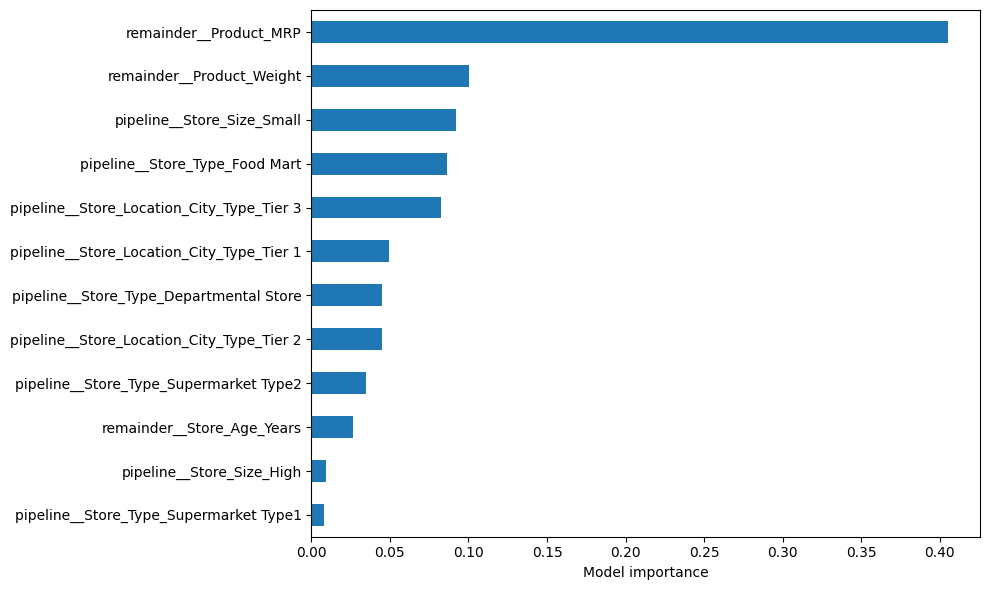

In [69]:
# Add feature importance to connect the fitted model to business interpretation
feature_names = saved_model[0].get_feature_names_out()
importance = pd.Series(saved_model[-1].feature_importances_, index=feature_names).sort_values(ascending=False)
display(importance.head(12).rename("Importance").to_frame())
importance.head(12).sort_values().plot.barh(figsize=(10, 6))
plt.xlabel("Model importance")
plt.tight_layout()
plt.show()

- This added view shows which encoded inputs the selected model uses most. Correlated store characteristics may share or substitute for each other's importance.
- Feature importance describes how the model makes predictions. It does not prove that changing an important feature will cause higher sales.
- Product MRP has the largest importance at about 40.5%, followed by Product Weight at about 10.0%. Store-size, format, and city-tier indicators make up much of the remaining importance.

In [70]:
# Compare test errors by the stores represented in the original data
test_errors = kart.loc[X_test.index, ["Store_Id", "Product_Store_Sales_Total"]].copy()
test_errors["Prediction"] = saved_model.predict(X_test)
test_errors["Absolute_Error"] = abs(test_errors.Product_Store_Sales_Total - test_errors.Prediction)
display(test_errors.groupby("Store_Id").agg(
    Test_Rows=("Absolute_Error", "size"), MAE=("Absolute_Error", "mean")
).round(2))

,Test_Rows,MAE
Store_Id,,
OUT001,489,147.25
OUT002,339,128.88
OUT003,415,158.31
OUT004,1386,86.56


- This extra check looks for uneven error between stores instead of relying only on one overall score.
- Store-level errors should guide the first rollout and the amount of manual review required for each store.

# **Deployment - Backend**

## Flask Web Framework

In [71]:
%%writefile backend_files/app.py

import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from flask import Flask, jsonify, request


superkart_api = Flask("SuperKart")
superkart_api.config["MAX_CONTENT_LENGTH"] = 2 * 1024 * 1024

# Load relative to this file so the API also works outside its Docker directory
model_dir = Path(__file__).resolve().parent
model = joblib.load(model_dir / "superkart_model.joblib")
metadata = json.loads((model_dir / "model_metadata.json").read_text())
features = metadata["features"]
numeric_features = metadata["numeric_features"]
categories = metadata["categories"]


def prepare_input(frame):
    """Check the input columns and report categories absent from training."""
    missing = [column for column in features if column not in frame.columns]
    if missing:
        raise ValueError("Missing columns: " + ", ".join(missing))
    if frame.empty:
        raise ValueError("Provide at least one product row.")
    if len(frame) > 5000:
        raise ValueError("A batch can contain at most 5,000 rows.")

    # Keep the same feature order and sugar labels used during training
    frame = frame.loc[:, features].copy()
    frame["Product_Sugar_Content"] = frame["Product_Sugar_Content"].replace(
        {"reg": "Regular"}
    )
    for column in numeric_features:
        frame[column] = pd.to_numeric(frame[column], errors="raise")
    numbers = frame[numeric_features].to_numpy(dtype=float)
    if not np.isfinite(numbers).all() or (numbers < 0).any():
        raise ValueError("Numeric inputs must contain finite, nonnegative values.")
    if (frame["Product_Allocated_Area"] > 1).any():
        raise ValueError("Product_Allocated_Area must be between 0 and 1.")
    if (frame["Store_Age_Years"] % 1 != 0).any():
        raise ValueError("Store_Age_Years must be a whole number.")

    warnings = []
    for column, known_values in categories.items():
        if frame[column].isna().any() or not frame[column].map(
            lambda value: isinstance(value, str) and bool(value.strip())
        ).all():
            raise ValueError(f"{column} must contain nonempty text.")
        unknown = sorted(set(frame[column]) - set(known_values))
        if unknown:
            warnings.append(f"{column} was not seen in training: {', '.join(unknown)}")
    return frame, warnings


@superkart_api.get("/")
def home():
    return "Welcome to the SuperKart System"


@superkart_api.get("/health")
def health():
    return jsonify({"status": "ok", "model": metadata["model_name"]})


@superkart_api.post("/v1/predict")
def predict_sales():
    # Validate requests before prediction instead of returning a server error
    payload = request.get_json(silent=True)
    if not isinstance(payload, dict):
        return jsonify({"error": "Send one product as a JSON object."}), 400
    try:
        input_data, warnings = prepare_input(pd.DataFrame([payload]))
        prediction = float(model.predict(input_data)[0])
        result = {"Sales": prediction}
        if warnings:
            result["warnings"] = warnings
        return jsonify(result)
    except (ValueError, TypeError) as error:
        return jsonify({"error": str(error)}), 400


@superkart_api.post("/v1/predictbatch")
def predict_sales_batch():
    if "file" not in request.files:
        return jsonify({"error": "Upload a CSV using the file field."}), 400
    try:
        input_data, warnings = prepare_input(pd.read_csv(request.files["file"]))
        predictions = model.predict(input_data).tolist()
        output = {str(i): round(pred, 2) for i, pred in enumerate(predictions)}
        response = jsonify(output)
        # Preserve the course's index-keyed response and put warnings in a header
        if warnings:
            response.headers["X-SuperKart-Warnings"] = json.dumps(warnings)
        return response
    except (ValueError, TypeError, pd.errors.ParserError) as error:
        return jsonify({"error": str(error)}), 400


if __name__ == "__main__":
    # Bind port 7860 for local checks; the Docker image uses Gunicorn
    superkart_api.run(host="0.0.0.0", port=7860, debug=False)

Overwriting backend_files/app.py


- The backend keeps the course routes for one JSON product and an uploaded CSV batch. It loads the saved pipeline once and returns its predictions.
- The model path is made relative to the application file, and basic input checks are added so missing columns and invalid numbers return a useful 400 response instead of a server error.
- A health route is added for checking the running container. Unknown categories produce a warning; batch predictions retain the course's row-index response format.
- The development server uses port 7860 with debug mode off. The Docker image uses Gunicorn for serving requests.

## Dependencies File

In [72]:
%%writefile backend_files/requirements.txt
pandas==2.2.2
numpy==2.0.2
scikit-learn==1.6.1
xgboost==2.1.4
joblib==1.4.2
flask==3.1.2
gunicorn==23.0.0

Overwriting backend_files/requirements.txt


- Model package versions match training so the serialized pipeline can be loaded consistently.
- Flask and Gunicorn replace the older pins. Unused backend dependencies are removed because this Flask service does not use them.

## Dockerfile

In [73]:
%%writefile backend_files/Dockerfile
# Python 3.12 supports the supplied package versions and is still supported
FROM python:3.12-slim

WORKDIR /app

# XGBoost needs the OpenMP runtime in the Linux container
RUN apt-get update && apt-get install -y --no-install-recommends libgomp1 \
    && rm -rf /var/lib/apt/lists/*
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY . .

EXPOSE 7860
# Two workers are sufficient for the course-sized deployment
CMD ["gunicorn", "-w", "2", "-b", "0.0.0.0:7860", "app:superkart_api"]

Overwriting backend_files/Dockerfile


- Python is changed from 3.9 to 3.12 because the supplied modern analysis packages need a compatible supported runtime.
- The Linux OpenMP library is added for XGBoost, and requirements are installed before application files so unchanged dependencies can use Docker's cache.
- Gunicorn uses two workers for this small deployment instead of the supplied four-worker setting.

# **Deployment - Frontend**

## Streamlit for Interactive UI

In [74]:
%%writefile frontend_files/app.py


import io
import json
import os

import pandas as pd
import requests
import streamlit as st


# Docker uses the backend service name; an environment variable also supports Codespaces
BACKEND_URL = os.environ.get("BACKEND_URL", "http://backend:7860").rstrip("/")

st.set_page_config(page_title="SuperKart Sales", layout="centered")
st.title("SuperKart System")
st.write("Enter the product and store details to estimate total sales revenue.")
st.caption("Estimates use the supplied dataset's revenue units and observation period.")

# Show training categories so the form does not silently send misspelled labels
with st.form("single_prediction"):
    Product_Weight = st.number_input("Product Weight", min_value=0.0, value=12.66)
    Product_Sugar_Content = st.selectbox(
        "Product Sugar Content", ["Low Sugar", "Regular", "No Sugar"]
    )
    Product_Allocated_Area = st.number_input(
        "Product Allocated Area", min_value=0.0, max_value=1.0,
        value=0.027, step=0.001, format="%.3f"
    )
    Product_MRP = st.number_input("Product MRP", min_value=0.0, value=117.08)
    Store_Size = st.selectbox("Store Size", ["Medium", "Small", "High"])
    Store_Location_City_Type = st.selectbox(
        "Store Location City Type", ["Tier 2", "Tier 1", "Tier 3"]
    )
    Store_Type = st.selectbox(
        "Store Type", ["Supermarket Type2", "Supermarket Type1", "Departmental Store", "Food Mart"]
    )
    Product_Id_char = st.selectbox("Product ID Character", ["FD", "DR", "NC"])
    Store_Age_Years = st.number_input("Store Age (2025 reference year)", min_value=0, value=16)
    Product_Type_Category = st.selectbox(
        "Product Type Category", ["Non Perishables", "Perishables"]
    )
    predict = st.form_submit_button("Predict", type="primary")

product_data = {
    "Product_Weight": Product_Weight,
    "Product_Sugar_Content": Product_Sugar_Content,
    "Product_Allocated_Area": Product_Allocated_Area,
    "Product_MRP": Product_MRP,
    "Store_Size": Store_Size,
    "Store_Location_City_Type": Store_Location_City_Type,
    "Store_Type": Store_Type,
    "Product_Id_char": Product_Id_char,
    "Store_Age_Years": Store_Age_Years,
    "Product_Type_Category": Product_Type_Category,
}

if predict:
    # A timeout and a clear error keep the page usable when the backend is unavailable
    try:
        response = requests.post(f"{BACKEND_URL}/v1/predict", json=product_data, timeout=30)
        if response.ok:
            result = response.json()
            st.success(f"Predicted Product Store Sales Total: {result['Sales']:,.2f}")
            for warning in result.get("warnings", []):
                st.warning(warning)
        else:
            st.error(response.json().get("error", "The prediction could not be completed."))
    except requests.RequestException:
        st.error("The prediction service could not be reached. Please try again.")

st.subheader("Batch Prediction")
st.write("Upload a CSV with the same ten feature columns used by the single prediction form.")
uploaded_file = st.file_uploader("Upload a CSV file", type=["csv"])

if uploaded_file is not None and st.button("Predict for Batch", type="primary"):
    try:
        content = uploaded_file.getvalue()
        response = requests.post(
            f"{BACKEND_URL}/v1/predictbatch",
            files={"file": (uploaded_file.name, content, "text/csv")},
            timeout=30,
        )
        if response.ok:
            results = response.json()
            # Map each numbered result back to its original CSV row
            batch_results = pd.read_csv(io.BytesIO(content))
            # Put the prediction first so it is visible before horizontal scrolling
            batch_results.insert(0, "Predicted_Sales", [results[str(i)] for i in range(len(batch_results))])
            st.success(f"Predictions completed for {len(batch_results)} products.")
            for warning in json.loads(response.headers.get("X-SuperKart-Warnings", "[]")):
                st.warning(warning)
            st.dataframe(batch_results, use_container_width=True)
            st.download_button(
                "Download predictions", batch_results.to_csv(index=False).encode("utf-8"),
                file_name="SuperKart_Batch_Predictions.csv", mime="text/csv"
            )
        else:
            st.error(response.json().get("error", "The batch could not be processed."))
    except (requests.RequestException, ValueError):
        st.error("Check the CSV and the prediction service, then try again.")


Overwriting frontend_files/app.py


- The form follows the low-code input fields and sends requests to the Flask backend rather than loading the model in the frontend.
- The store dropdowns use training labels, and the store-age field states its fixed 2025 reference year. The unsupported Type3 option is removed from the single-entry form.
- A form groups the inputs, request timeouts handle an unavailable backend, and the batch table keeps each prediction beside its original row. The course's horizontal dictionary display is changed to a row-based table with a CSV download.
- The backend address can be supplied through an environment variable. The Docker default remains the backend service on the shared network.
- The currency symbol is removed because the data dictionary does not state a currency. The output is described in the original revenue units.
- The batch prediction column is placed first so the estimate is visible before horizontal scrolling.

## Dependencies File

In [75]:
%%writefile frontend_files/requirements.txt
pandas==2.2.2
numpy==2.0.2
requests==2.32.4
streamlit==1.43.2

Overwriting frontend_files/requirements.txt


- The frontend keeps the supplied Streamlit version and uses the same Pandas and NumPy versions as the rest of the project.
- Requests is updated from the older low-code pin so both services use one version.

## Dockerfile

In [76]:
%%writefile frontend_files/Dockerfile
# Match the supported Python version used for the backend
FROM python:3.12-slim

WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY . .

EXPOSE 8501
# Keep Streamlit's request protection enabled
CMD ["streamlit", "run", "app.py", "--server.port=8501", "--server.address=0.0.0.0", "--browser.gatherUsageStats=false"]

Overwriting frontend_files/Dockerfile


- The frontend also uses Python 3.12, and installs requirements before copying the remaining files for better build caching.
- The supplied option that disabled request protection is removed. Streamlit's normal protection stays enabled, and usage-statistics collection is turned off.

## Run both containers

In [77]:
%%writefile compose.yaml
name: superkart

services:
  backend:
    build: ./backend_files
    ports:
      - "7860:7860"
    healthcheck:
      test: ["CMD", "python", "-c", "import urllib.request; urllib.request.urlopen('http://localhost:7860/health', timeout=5)"]
      interval: 10s
      timeout: 6s
      retries: 6
      start_period: 15s
    restart: unless-stopped

  frontend:
    build: ./frontend_files
    ports:
      - "8501:8501"
    environment:
      BACKEND_URL: http://backend:7860
    depends_on:
      backend:
        condition: service_healthy
    healthcheck:
      test: ["CMD", "python", "-c", "import urllib.request; urllib.request.urlopen('http://localhost:8501/_stcore/health', timeout=5)"]
      interval: 10s
      timeout: 6s
      retries: 6
      start_period: 15s
    restart: unless-stopped

Overwriting compose.yaml


- Docker Compose is added to run the two supplied containers on one network with one command.
- The frontend calls the backend by service name. Health checks wait for the model API before the frontend starts.

In [78]:
# Start the same Docker services locally or inside a Codespace
# Colab can instead call an already-running Codespace through MODEL_ROOT_URL
if shutil.which("docker"):
    build = subprocess.run(
        ["docker", "compose", "up", "--build", "-d", "--wait"],
        text=True, capture_output=True,
    )
    if build.returncode:
        raise RuntimeError(build.stderr[-5000:])
    status = subprocess.run(["docker", "compose", "ps"], text=True, capture_output=True, check=True)
    print(status.stdout)
else:
    print("Docker is not available in this runtime. Use the running Codespace URL for inference below.")

NAME                   IMAGE                COMMAND                  SERVICE    CREATED         STATUS                   PORTS
superkart-backend-1    superkart-backend    "gunicorn -w 2 -b 0.…"   backend    4 minutes ago   Up 4 minutes (healthy)   0.0.0.0:7860->7860/tcp, [::]:7860->7860/tcp
superkart-frontend-1   superkart-frontend   "streamlit run app.p…"   frontend   4 minutes ago   Up 4 minutes (healthy)   0.0.0.0:8501->8501/tcp, [::]:8501->8501/tcp



- This added cell builds and starts the actual services and prints their status. A successful prediction below checks the deployed model, not a separate notebook-only function.
- In Colab, Docker is not available, so the notebook can use the forwarded address of the same running deployment instead.

# **Pushing Deployment Files to GitHub**

In [79]:
# Use the existing GitHub login instead of embedding a personal access token
# Keep the notebook folder names in GitHub so all relative paths stay valid
REPO_NAME = "pradeeptathineni/superkart-model-deployment"
REPO_URL = "https://github.com/" + REPO_NAME
if shutil.which("gh"):
    repository = subprocess.run(
        ["gh", "repo", "view", REPO_NAME, "--json", "url,isPrivate"],
        text=True, capture_output=True, check=True,
    )
    print(repository.stdout)
else:
    print("Deployment repository:", REPO_URL)

{
  "isPrivate": true,
  "url": "https://github.com/pradeeptathineni/superkart-model-deployment"
}



- GitHub authentication uses the existing CLI login rather than copying a token into the notebook. The private repository contains the deployment files and the saved model.
- The repository is pushed from the project folder after execution. Keeping publishing outside Run all avoids creating a new repository or commit each time the analysis is rerun.
- A dev-container file is included so a Codespace can build and start both Docker services automatically. Open port 8501 for the app and forward port 7860 for API requests.
- The repository keeps backend_files and frontend_files instead of renaming them during upload, so the notebook and Docker files use the same paths.
- The dev-container Dockerfile removes an unused Yarn package source whose missing signing key blocked Docker setup. This is documented in the Dockerfile comment, and normal package signature checks remain enabled.
- The SSH feature is added to the dev-container configuration so the Codespaces CLI can inspect the running services during deployment.

## Deployment addresses

In [80]:
# Use the real forwarded URL in Codespaces; localhost serves the Docker run here
model_root_url = os.environ.get("MODEL_ROOT_URL", "http://127.0.0.1:7860").rstrip("/")
frontend_url = os.environ.get("FRONTEND_URL", "http://127.0.0.1:8501").rstrip("/")
print("Backend:", model_root_url)
print("Frontend:", frontend_url)
response = requests.get(model_root_url + "/health", timeout=30)
response.raise_for_status()
print("Backend health:", response.json())
frontend_health = requests.get(frontend_url + "/_stcore/health", timeout=30)
frontend_health.raise_for_status()
print("Frontend health:", frontend_health.text)

Backend: https://superkart-deployment-pj6wp64jxg727xpw-7860.app.github.dev
Frontend: https://superkart-deployment-pj6wp64jxg727xpw-8501.app.github.dev


Backend health: {'model': 'Tuned Random Forest', 'status': 'ok'}


Frontend health: ok


- These addresses are the services used by this execution. A Codespace address must point to its running forwarded port, and access stops when the Codespace is stopped.
- The URL cell is changed to read configuration from the environment so the same notebook works with local Docker and the cloud deployment.

# **Inferencing using Flask API**

## Online inference

In [81]:
# Keep the course's example product and endpoint
model_url = model_root_url + "/v1/predict"
model_batch_url = model_root_url + "/v1/predictbatch"
payload = {
    "Product_Weight": 12.66,
    "Product_Sugar_Content": "Low Sugar",
    "Product_Allocated_Area": 0.027,
    "Product_MRP": 117.08,
    "Store_Size": "Medium",
    "Store_Location_City_Type": "Tier 2",
    "Store_Type": "Supermarket Type2",
    "Product_Id_char": "FD",
    "Store_Age_Years": 16,
    "Product_Type_Category": "Non Perishables",
}
response = requests.post(model_url, json=payload, timeout=30)
response.raise_for_status()
print("HTTP status:", response.status_code)
print(response.json())
local_prediction = float(saved_model.predict(pd.DataFrame([payload]))[0])
np.testing.assert_allclose(response.json()["Sales"], local_prediction, rtol=1e-6)
print("The API prediction matches the saved pipeline.")

HTTP status: 200
{'Sales': 2909.647516468671}


The API prediction matches the saved pipeline.


- The example payload follows the supplied full-code notebook exactly. The request adds a timeout and a status check so a failed request cannot be mistaken for a prediction.
- The extra comparison checks the live API against the saved pipeline. The response must contain a numeric Sales value and match within floating-point tolerance.
- This is a revenue estimate, not a quantity of units to order.

## Batch inference

In [82]:
batch_dataset = pd.read_csv("Batch_Data_SuperKart.csv")
# Preserve the supplied multipart file contract and original CSV row order
batch_input = {"file": batch_dataset.to_csv(header=True, index=False).encode("utf-8")}
response = requests.post(model_batch_url, files=batch_input, timeout=30)
response.raise_for_status()
print("HTTP status:", response.status_code)
print(response.json())
batch_predictions = batch_dataset.copy()
batch_predictions["Predicted_Sales"] = [response.json()[str(i)] for i in range(len(batch_dataset))]
np.testing.assert_allclose(
    batch_predictions.Predicted_Sales, saved_model.predict(batch_dataset), atol=0.011, rtol=1e-6
)
display(batch_predictions)
batch_predictions.to_csv("results/SuperKart_Batch_Predictions.csv", index=False)
for warning in json.loads(response.headers.get("X-SuperKart-Warnings", "[]")):
    print("Review:", warning)

HTTP status: 200
{'0': 3880.57, '1': 3353.52, '2': 3778.46, '3': 1736.72, '4': 4113.81, '5': 4870.9, '6': 2476.89, '7': 2356.16, '8': 4992.84, '9': 2303.82}


,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_MRP,Store_Size,Store_Location_City_Type,Store_Type,Product_Id_char,Store_Age_Years,Product_Type_Category,Predicted_Sales
0,12.66,Low Sugar,0.027,117.08,Small,Tier 1,Supermarket Type1,FD,16,Perishables,3880.57
1,8.20,Regular,0.045,85.50,Medium,Tier 2,Supermarket Type2,DR,22,Non Perishables,3353.52
2,15.40,No Sugar,0.012,210.75,High,Tier 3,Departmental Store,NC,8,Non Perishables,3778.46
3,5.75,Regular,0.060,55.20,Small,Tier 1,Food Mart,FD,30,Perishables,1736.72
4,19.30,Low Sugar,0.033,145.60,Medium,Tier 2,Supermarket Type3,DR,12,Non Perishables,4113.81
5,10.00,No Sugar,0.050,92.40,High,Tier 1,Supermarket Type1,NC,5,Non Perishables,4870.90
6,7.85,Regular,0.018,178.90,Small,Tier 3,Supermarket Type2,FD,19,Perishables,2476.89
7,14.10,Low Sugar,0.041,63.25,Medium,Tier 2,Food Mart,DR,27,Perishables,2356.16
8,3.50,No Sugar,0.009,250.00,High,Tier 1,Departmental Store,NC,10,Non Perishables,4992.84
9,11.25,Regular,0.055,130.45,Small,Tier 3,Supermarket Type3,FD,14,Perishables,2303.82


Review: Store_Type was not seen in training: Supermarket Type3


- The supplied ten-row file is sent as a multipart CSV using the same file field as the course example.
- A row-based table and an equality check are added to confirm that each API result belongs to the correct CSV row. The two-decimal rounding follows the course batch endpoint.
- Supermarket Type3 appears in the batch file but not in training. Its rows still receive estimates because the encoder ignores unseen categories, and the warning makes that limitation visible.
- Several batch combinations of store size, type, and city tier differ from the four training stores. They need review even when their individual category labels are known.
- There are no actual sales labels in this batch, so these outputs demonstrate inference rather than measured batch accuracy.

## Invalid-input checks

In [83]:
# Add two checks for the validation added to the supplied API
missing_input = requests.post(model_url, json={"Product_MRP": 100}, timeout=30)
negative_input = requests.post(model_url, json={**payload, "Product_Weight": -1}, timeout=30)
for label, result in [("Missing columns", missing_input), ("Negative weight", negative_input)]:
    assert result.status_code == 400
    print(label, ":", result.status_code, result.json())

Missing columns : 400 {'error': 'Missing columns: Product_Weight, Product_Sugar_Content, Product_Allocated_Area, Store_Size, Store_Location_City_Type, Store_Type, Product_Id_char, Store_Age_Years, Product_Type_Category'}
Negative weight : 400 {'error': 'Numeric inputs must contain finite, nonnegative values.'}


- Both requests return a clear 400 response. The API rejects incomplete or physically invalid inputs before model prediction.
- These checks are added with the input-validation change; they do not claim that the small educational deployment covers every production concern.

## Frontend verification

,Browser result
frontend_url,https://superkart-deployment-pj6wp64jxg727xpw-...
single_result,"Predicted Product Store Sales Total: 2,909.65"
batch_rows,10
unseen_category_warning,True
download_matches_api,True
original_row_order_preserved,True


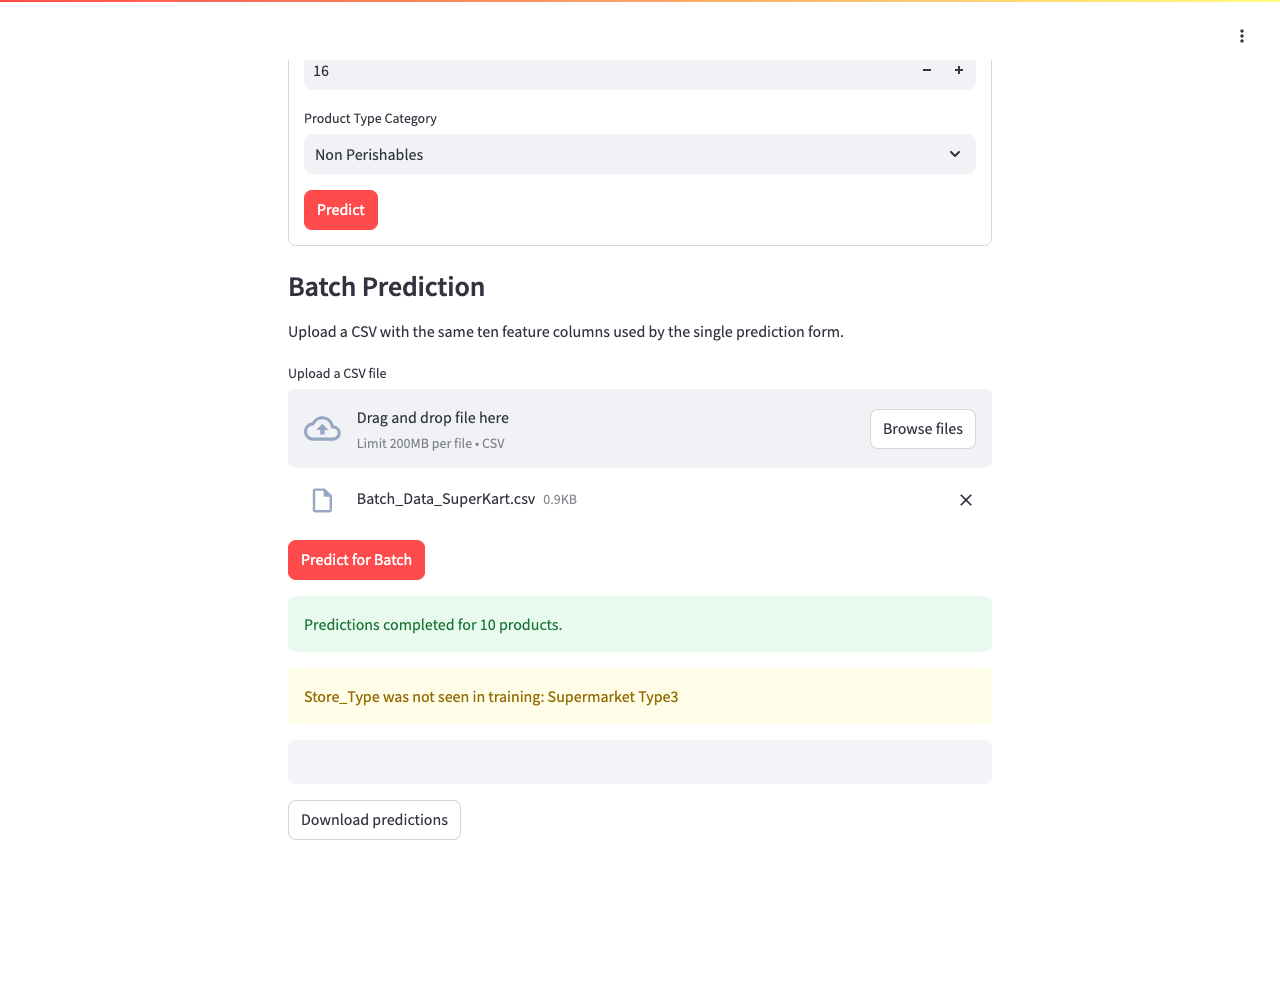

In [84]:
# Show the recorded browser checks for the actual single and batch workflows
frontend_checks = json.loads(Path("results/frontend_checks.json").read_text())
display(pd.Series(frontend_checks).to_frame("Browser result"))
from IPython.display import Image
display(Image(filename="results/frontend_batch.png", width=900))

- The browser submitted one product, uploaded the supplied ten-row CSV, and downloaded the results through the actual Streamlit page.
- The downloaded predictions match the API and preserve the original input order. The screenshot also shows the warning for the unfamiliar store type.
- This added evidence checks the complete frontend-to-backend path instead of relying only on a page health response.

## Comparison with public solutions

In [85]:
# Compare recorded reference outputs; model choices and tuning grids differ
reference_results = pd.DataFrame([
    ["RashmiJK", "Random Forest", 295.997098, 0.923438],
    ["RashmiJK", "XGBoost", 310.728392, 0.915627],
    ["iOSNinja", "Tuned Gradient Boosting", 299.190019, 0.921777],
    ["iOSNinja", "Tuned XGBoost", 311.352131, 0.915288],
], columns=["Reference", "Model", "Test RMSE", "Test R-squared"])
display(reference_results)
print("This notebook's selected model:", final_model_name)
display(model_performance_regression(saved_model, X_test, y_test))

,Reference,Model,Test RMSE,Test R-squared
0,RashmiJK,Random Forest,295.997098,0.923438
1,RashmiJK,XGBoost,310.728392,0.915627
2,iOSNinja,Tuned Gradient Boosting,299.190019,0.921777
3,iOSNinja,Tuned XGBoost,311.352131,0.915288


This notebook's selected model: Tuned Random Forest


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,290.789943,114.630365,0.926108,0.925484,0.051492


- The public notebooks use the same retail task and report test R-squared values around 0.91 to 0.93. Their saved output is used as a reasonableness check, not as a replacement for running this notebook.
- The course's fixed split and feature meanings are kept here. Tuning ranges, model type, library versions, and numeric preprocessing can explain small differences.
- The exact-name search also found an unfilled master notebook, which cannot validate results. Another Docker/Codespaces repository was checked for the two-service deployment flow.
- The reference links and inspected revisions are saved in solution-links.txt. The supplied low-code notebook remains the source for the implementation structure and directly reused code.
- The Random Forest baseline here is within 0.06 RMSE of RashmiJK's saved output. The XGBoost baseline differs by about 1.28 RMSE. Those small differences are consistent with implementation and numeric preprocessing differences; there is no large unexplained performance jump.

# **Actionable Insights and Business Recommendations**

- Tuned Random Forest is selected, with test R-squared of 0.9261, RMSE of 290.79, MAE of 114.63, and MAPE of about 5.15%. These figures describe this split and the four available stores; they do not establish accuracy for a future quarter.
- Start with a supervised rollout at the four stores represented in the data. Use revenue estimates to support purchasing decisions, and compare the estimates with actual results before expanding.
- Give Fruits and Vegetables and Snack Foods close availability checks because they contribute the largest observed revenue totals. Balance that attention with spoilage, margin, and stockout information, which this file does not contain.
- Give OUT004 the largest total planning attention, while studying OUT003's higher revenue per record. The two measures describe different strengths and should not be mixed together.
- Do not assume that adding shelf area, raising price, or opening a Tier 2 store will create the relationships shown here. Review comparable products and stores and test changes before committing money.
- Collect dated weekly sales, units sold, promotions, holidays, stockouts, and product costs. Those additions are needed for a defensible next-quarter forecast and useful purchasing quantities.
- Monitor error by store and product category, flag unfamiliar inputs, and retrain when errors or the assortment change. Keep predictions available for review alongside the inputs and model version.
- Before wider use, add access control, request limits, and service monitoring. The current Docker setup demonstrates the complete prediction path; ongoing business use needs operational ownership.

## Note to the Great Learning team

- Thank you to the Great Learning team for the program. My biggest criticism was learning and using material that was very obviously one to two years old, especially when tools and packages had already moved on. I would have liked more current examples and clearer updates. Still, I am glad I participated. I learned a lot, and working through these projects helped me connect the analysis, modeling, and deployment steps.